# Detecting Moving Objects in DAS Recordings

**Computer Vision - Project 1 (2026), grade-4 version.**
Authors: **Jakub Banasiak (164184)** and **Mateusz Niezgódka (164224)** (pair project). Data: fibre-optic cable along Jana Pawła II
street, 2024-05-07.

**Abstract.** In a Distributed Acoustic Sensing (DAS) time-space image, a passing vehicle draws a
slanted line, and the slope of the line is its velocity. We detect the **thick, clearly visible
lines** (trams, heavy trucks) in three continuous 2-minute segments of real data and compute the
velocity of every detected object. The method uses only classical, vectorised processing
(NumPy, OpenCV, scikit-image, Matplotlib):

1. **pre-processing** - common-mode removal, a 60-312.5 Hz band-pass, an RMS energy envelope
   and a log normalisation;
2. **enhancement** - an f-k fan filter that keeps only moving objects (separately for each
   direction) and a bank of matched line filters;
3. **detection** - a data-driven threshold, connected components and RANSAC line fits;
4. **grouping** - one averaged line per vehicle; its slope gives the velocity.

In [1]:
import csv
import json
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "report" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, RES = ROOT / "report" / "figures", ROOT / "outputs" / "results"

from das import config  # noqa: E402


def fig(name: str, width: int | None = None) -> None:
    """Show a report figure (PNG or JPEG, embedded in the HTML)."""
    display(Image(filename=str(next(FIG.glob(name + ".*"))), width=width))


def read_csv(name: str) -> list[dict]:
    with open(RES / name, newline="", encoding="utf-8") as fh:
        return list(csv.DictReader(fh))


def read_json(name: str) -> dict:
    return json.loads((RES / name).read_text(encoding="utf-8"))


def fmt(v, nd: int = 3) -> str:
    if v is None or v == "":
        return "-"
    if isinstance(v, str):
        try:
            v = float(v) if any(c in v for c in ".e") else int(v)
        except ValueError:
            return v
    if isinstance(v, float):
        if not np.isfinite(v):
            return "-"
        return f"{v:.3g}" if (abs(v) >= 1e4 or 0 < abs(v) < 1e-3) else f"{v:.{nd}f}"
    return str(v)


def table(rows: list[dict], cols: list[str], headers: list[str] | None = None, nd: int = 3) -> None:
    """Render a list of dicts as a Markdown table."""
    esc = lambda s: str(s).replace("|", "\\|")  # noqa: E731  (pipes inside cells)
    lines = ["| " + " | ".join(map(esc, headers or cols)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(esc(fmt(r.get(c, ""), nd)) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


# result tables used in the text (all numbers below come from the code's outputs)
REAL = {r["segment"]: r for r in read_csv("eval_real.csv")}
SYN = {r["sample"]: r for r in read_csv("eval_synthetic.csv")}
EXP = {r["variant"]: r for r in read_csv("experiments.csv")}
SUMM = [r for r in read_csv("pipeline_summary.csv") if r["kind"] == "segment"]
f = lambda v, nd=3: f"{float(v):.{nd}f}"  # noqa: E731

In [2]:
ra, sa = REAL["ALL"], SYN["ALL"]
t = [float(r["total_s"]) for r in SUMM]
display(Markdown(f"""
**Results.** {' / '.join(r['n_objects'] for r in SUMM)} objects were detected in the three
segments, in {min(t):.1f}-{max(t):.1f} s of processing per 2-minute segment.
- Against our manual labels of the real segments: thick-line recall **{f(ra['recall_thick'])}**
  ({ra['tp_thick']}/{ra['n_ref_thick']}), precision **{f(ra['precision'])}**, F1 {f(ra['f1'])}.
- On the synthetic dataset (true ground truth): thick-line recall **{f(sa['recall_thick'])}**
  ({sa['tp_thick']}/{sa['n_ref_thick']}), precision {f(sa['precision'])}, velocity error
  **{f(sa['vel_mae_thick'], 1)} km/h** (MAPE {f(sa['vel_mape_thick'], 1)} %).

Every step of the method is justified by an experiment (section 11).
"""))


**Results.** 13 / 17 / 13 objects were detected in the three
segments, in 1.1-1.2 s of processing per 2-minute segment.
- Against our manual labels of the real segments: thick-line recall **0.913**
  (21/23), precision **0.791**, F1 0.847.
- On the synthetic dataset (true ground truth): thick-line recall **0.980**
  (48/49), precision 0.925, velocity error
  **2.9 km/h** (MAPE 3.8 %).

Every step of the method is justified by an experiment (section 11).


## 1. Introduction and data

**DAS principle.** Laser pulses are sent into an optical fibre. The phase of the light scattered
back from every section of the fibre changes when that section is strained, so a cable buried
along a street works as a line of vibration sensors (one per channel).

**Data.**
- 259 files of 10 s, named by their start time (HHMMSS). Each file is a 6250 × 52 matrix: rows =
  time (dt = 1.6 ms, 625 Hz), columns = position along the fibre (dx = 5.1065 m, ≈ 266 m in
  total).
- The files form two continuous runs: 09:00:17-09:02:37 and 09:02:52-09:43:42. A 2-minute
  segment is 12 consecutive files of one run (75 000 × 52 values).

**Segment boundaries.**
- The 12 files are joined **before** any processing, so a line that crosses a file boundary is
  one continuous line. We checked that consecutive files are continuous.
- The FFT filters treat the signal as periodic. The segment is therefore loaded with one extra
  file on each side, which is cut off after the band-pass and the envelope, so the edge errors
  fall into the part that is thrown away.
- A vehicle that is on the cable when the segment starts or ends is kept if its visible part is
  at least 40 m long. Its velocity is computed from the visible part only.

**What we look for.** A vehicle moving with velocity v draws the line $t(x) = t_0 + x / v$.
Trams and heavy trucks give **thick, strong lines**; cars give fainter, thinner lines. For grade 4,
the thick lines and their velocities are required.

**Segments (pair work).** Two segments are assigned in the course spreadsheet; as a pair we
chose a third one that does not overlap them:

In [3]:
from datetime import datetime, timedelta  # noqa: E402

eda = {s["name"]: read_json(f"eda_{s['name']}.json") for s in config.SEGMENTS}
rows = []
for s in config.SEGMENTS:
    t0 = datetime.strptime(s["start"], "%H%M%S")
    rows.append({**s, "start_clock": t0.strftime("%H:%M:%S"),
                 "end": (t0 + timedelta(seconds=10 * s["n_files"])).strftime("%H:%M:%S"),
                 **eda[s["name"]]["activity"]})
table(rows, ["name", "owner", "kind", "start_clock", "end", "active_fraction", "n_events"],
      ["segment", "analysed by", "kind", "start", "end", "active fraction", "traffic episodes"])

| segment | analysed by | kind | start | end | active fraction | traffic episodes |
|---|---|---|---|---|---|---|
| seg_kuba | Kuba | assigned | 09:04:52 | 09:06:52 | 0.118 | 6 |
| seg_mateusz | Mateusz | assigned | 09:32:22 | 09:34:22 | 0.099 | 2 |
| seg_own | Kuba + Mateusz | own | 09:11:52 | 09:13:52 | 0.258 | 10 |

**Why seg_own = 09:11:52-09:13:52.** We ranked every admissible 2-minute window (no overlap with
the assigned segments) by its traffic activity, i.e. the share of (1 s × channel) cells whose RMS
exceeds 3× the channel's reference level. This window had the highest activity, and it has
traffic in **both directions** with crossing lines, so it is the most demanding segment.

The whole recording as consecutive 2-minute panels (log RMS in 1 s × channel cells):

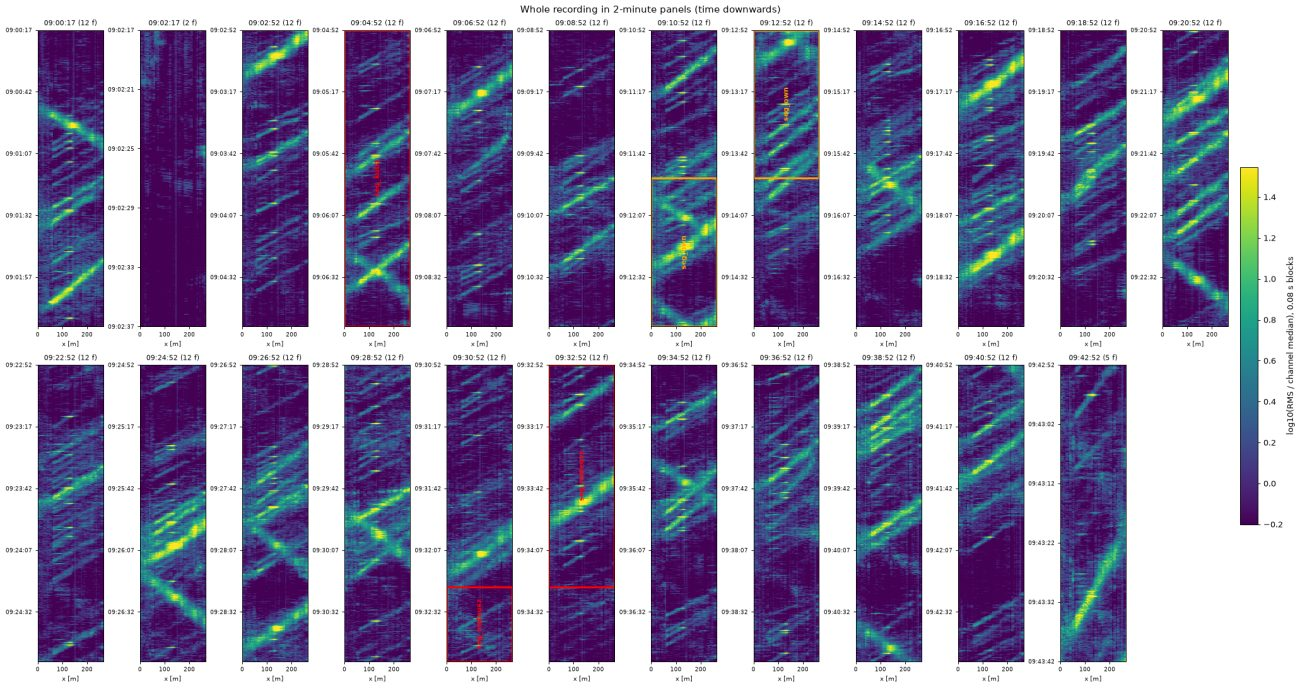

In [4]:
fig("eda_global_overview")

## 2. Exploratory data analysis

Basic statistics of the **whole dataset** (all 259 files, ≈ 84 million values, updated file by
file with running formulas so the data never has to be in memory at once) and of the **three
segments**:

In [5]:
g = read_json("eda_global.json")["global"]
# robust σ of the whole dataset: 1.4826 · median |x| (the median of the data is 0)
g = {**g, "robust_sigma": f"≈ {1.4826 * g['abs_p50']:.3g}"}
rows = [{"data": "all 259 files", **g}] + [{"data": n, **d["describe"]} for n, d in eda.items()]
table(rows, ["data", "mean", "std", "robust_sigma", "skewness", "kurtosis", "max_abs"],
      ["data", "mean", "std", "robust σ (1.4826·MAD)", "skewness", "excess kurtosis", "max |x|"])

| data | mean | std | robust σ (1.4826·MAD) | skewness | excess kurtosis | max \|x\| |
|---|---|---|---|---|---|---|
| all 259 files | 1.4e-10 | 4.85e-07 | ≈ 1.21e-07 | 0.902 | 434.755 | 7.18e-05 |
| seg_kuba | -1.94e-12 | 5.02e-07 | 1.15e-07 | 1.521 | 973.904 | 7.18e-05 |
| seg_mateusz | 2.17e-10 | 4.83e-07 | 1.11e-07 | 1.102 | 323.663 | 4.47e-05 |
| seg_own | 1.46e-10 | 7e-07 | 1.86e-07 | 0.410 | 193.726 | 4.24e-05 |

**What the numbers mean.**
- **Mean ≈ 0**: the fibre is stretched and compressed in turn, so the signal oscillates around zero.
- **std ≈ 4 × robust σ**: the std is inflated by a few very strong values (passing vehicles),
  while the robust σ (from the median absolute deviation) measures the background noise. We
  therefore use the robust σ for all thresholds.
- **Skewness 0.4-1.5**: roughly symmetric, as expected for vibrations.
- **Excess kurtosis in the hundreds** (0 for Gaussian noise) and **max |x| ≈ 150 × std**: the
  signal is mostly quiet with rare, very strong bursts.

**Histogram of all values** (left, log vertical axis) against two Gaussians (orange: same std,
green: σ = robust σ): the peak is much narrower and the tails much longer than any Gaussian.
Right: the distribution of |x| with its percentiles. About 2 % of the values are exactly zero
(the data are quantised in steps of 2.5·10⁻⁹).

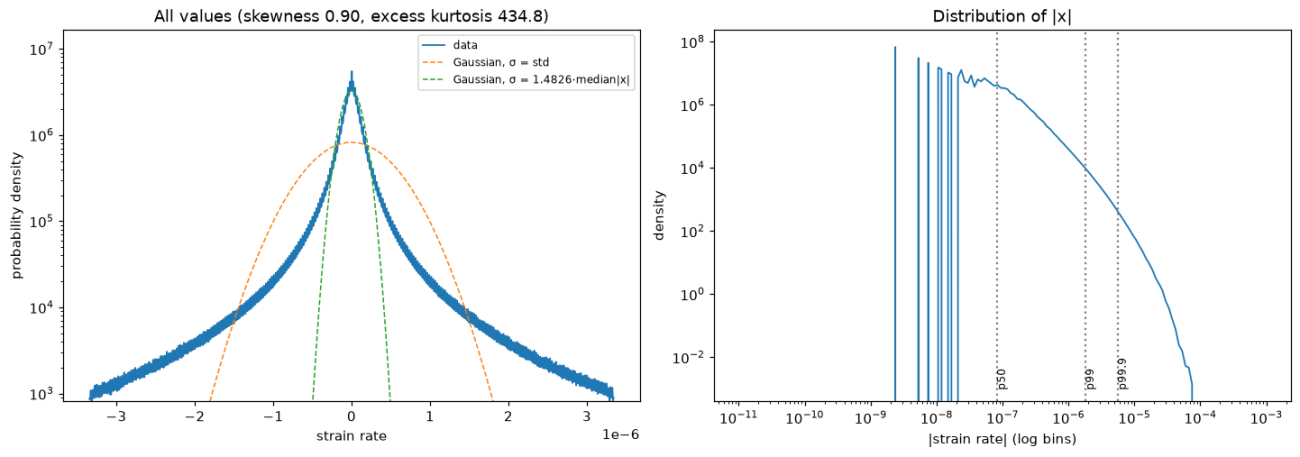

In [6]:
fig("eda_global_histograms")

**Variability along the cable and over time** (all files).
- Along the cable (first figure): RMS, a bad-channel test, kurtosis and the correlation with the
  neighbouring channel for every channel. Only channel 25 (≈ 128 m) slightly crosses the
  bad-channel limit. Its neighbours are also louder, so this is a physical "hotspot" of the
  road or track, not a broken sensor, and it is kept.
- Over time (second figure): quiet and busy periods alternate during the whole 40 minutes. A
  busy file is about 6× louder than a quiet one, so a fixed threshold would not work.

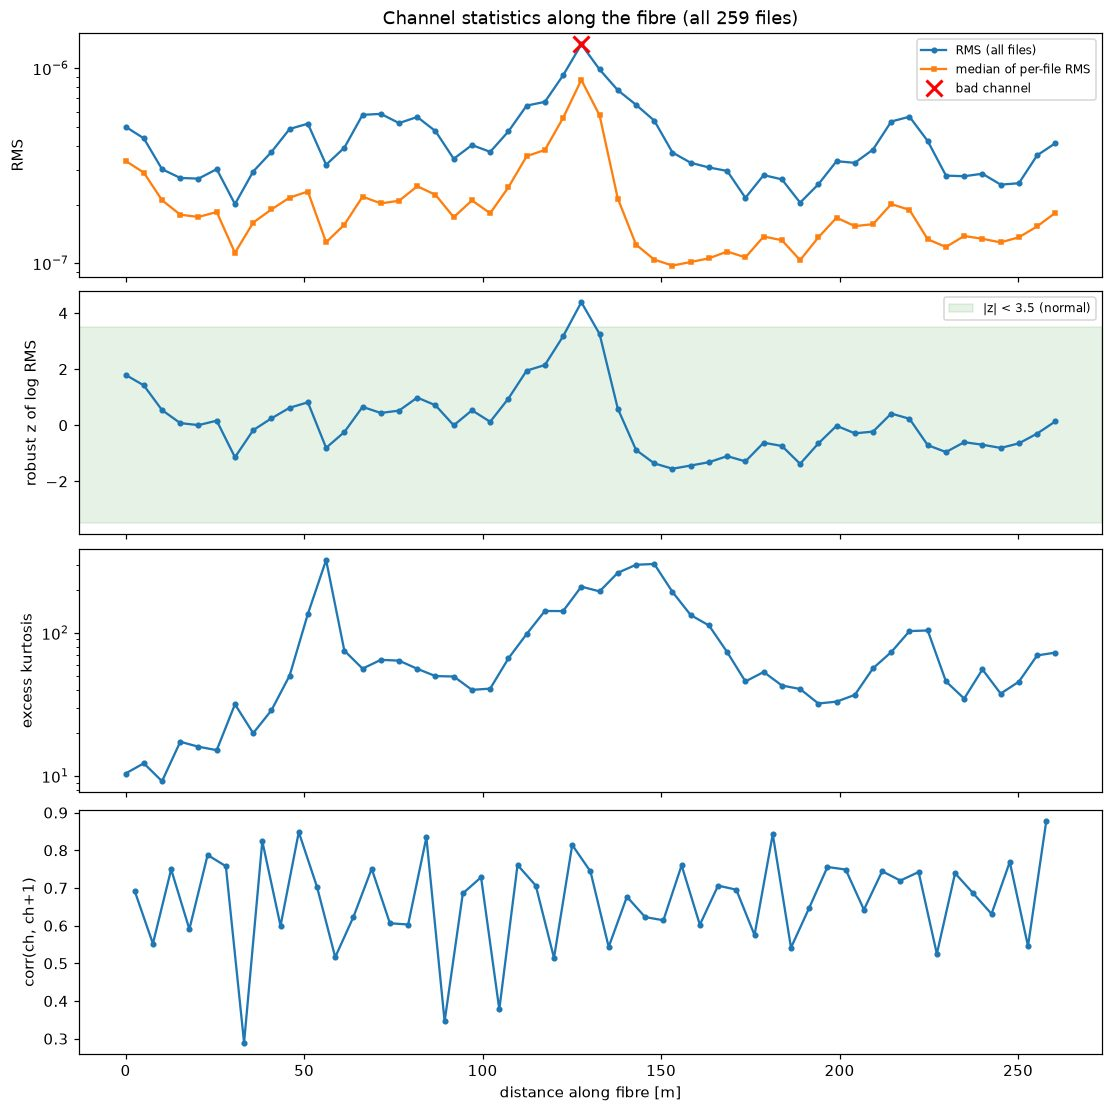

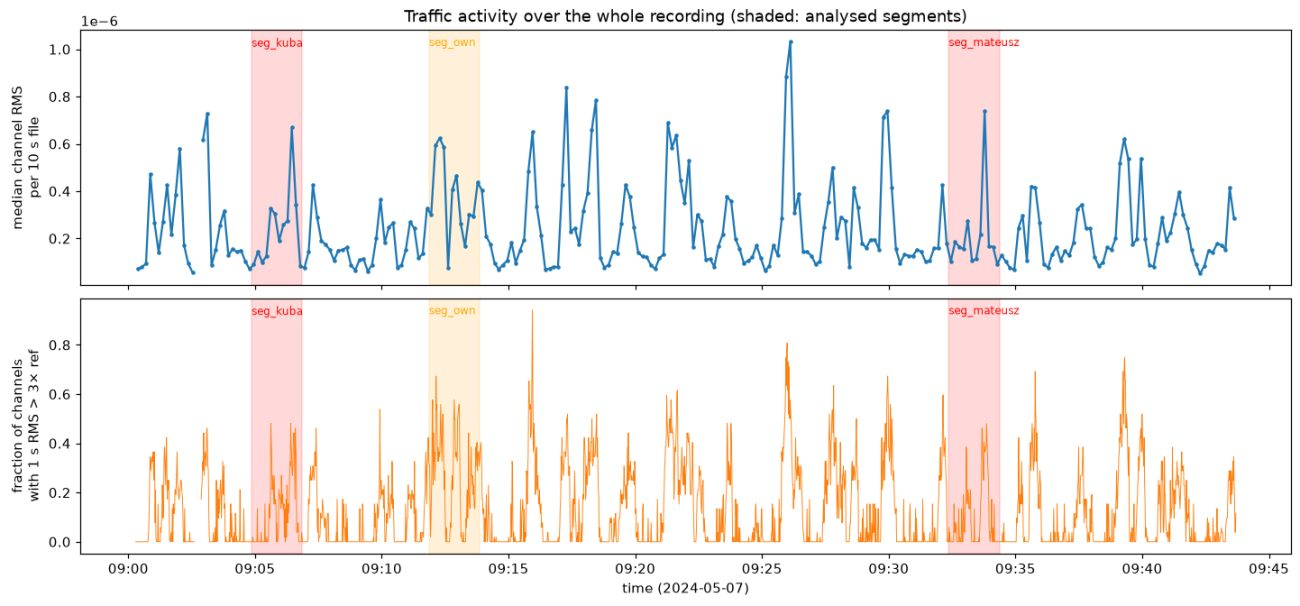

In [7]:
fig("eda_global_channel_profile")
fig("eda_global_activity_timeline")

**Linear vs logarithmic display** (seg_kuba) and **the raw signal** (seg_own). On a linear scale
only the strongest lines are visible; after dividing every channel by its median and taking the
logarithm all lines appear. The raw values swing up and down many times per second, so a vehicle
is a burst of vibration *energy* - this is why the method works on the energy envelope.

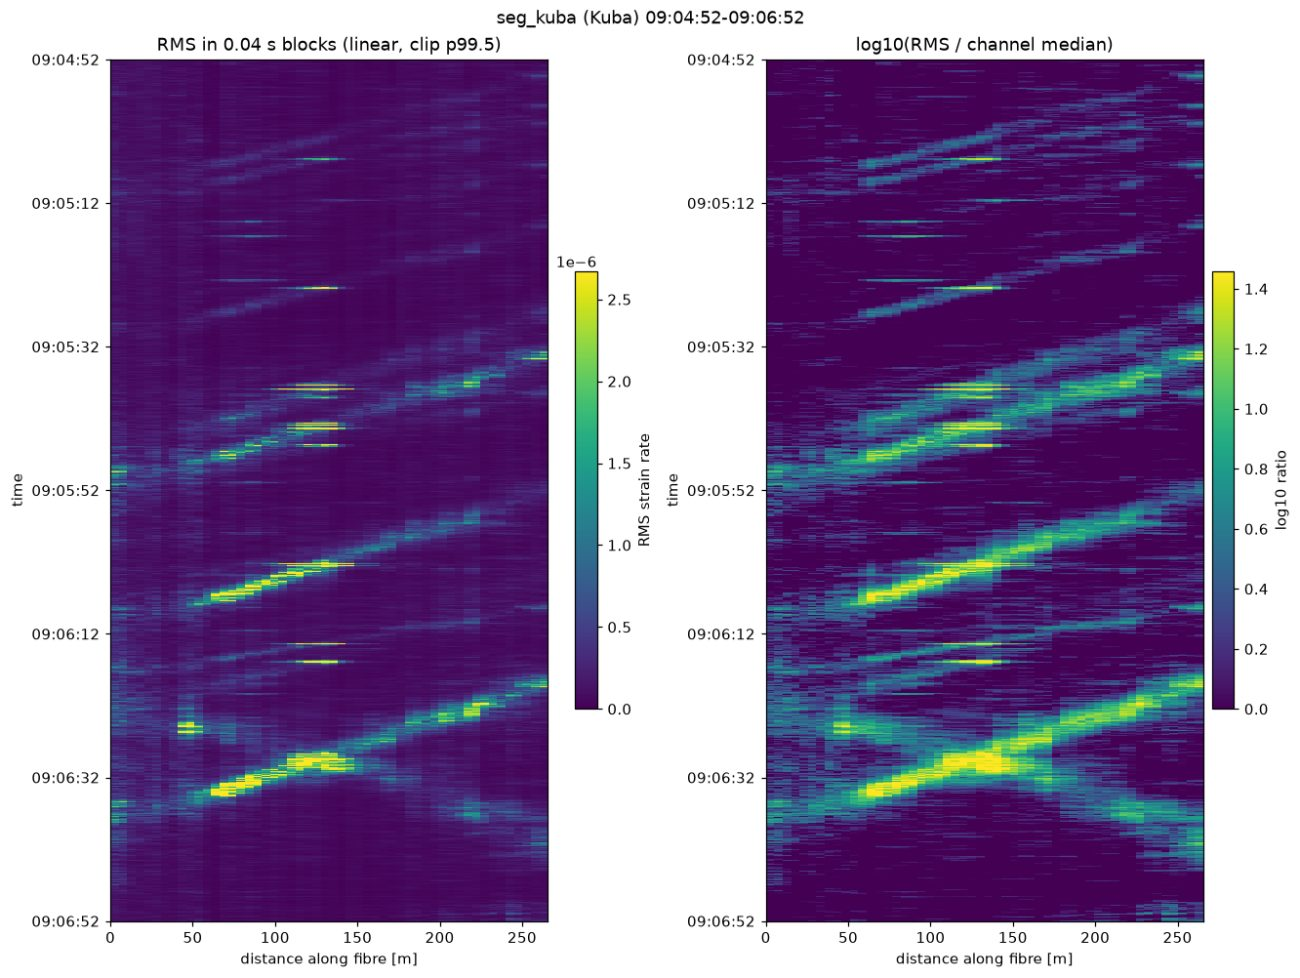

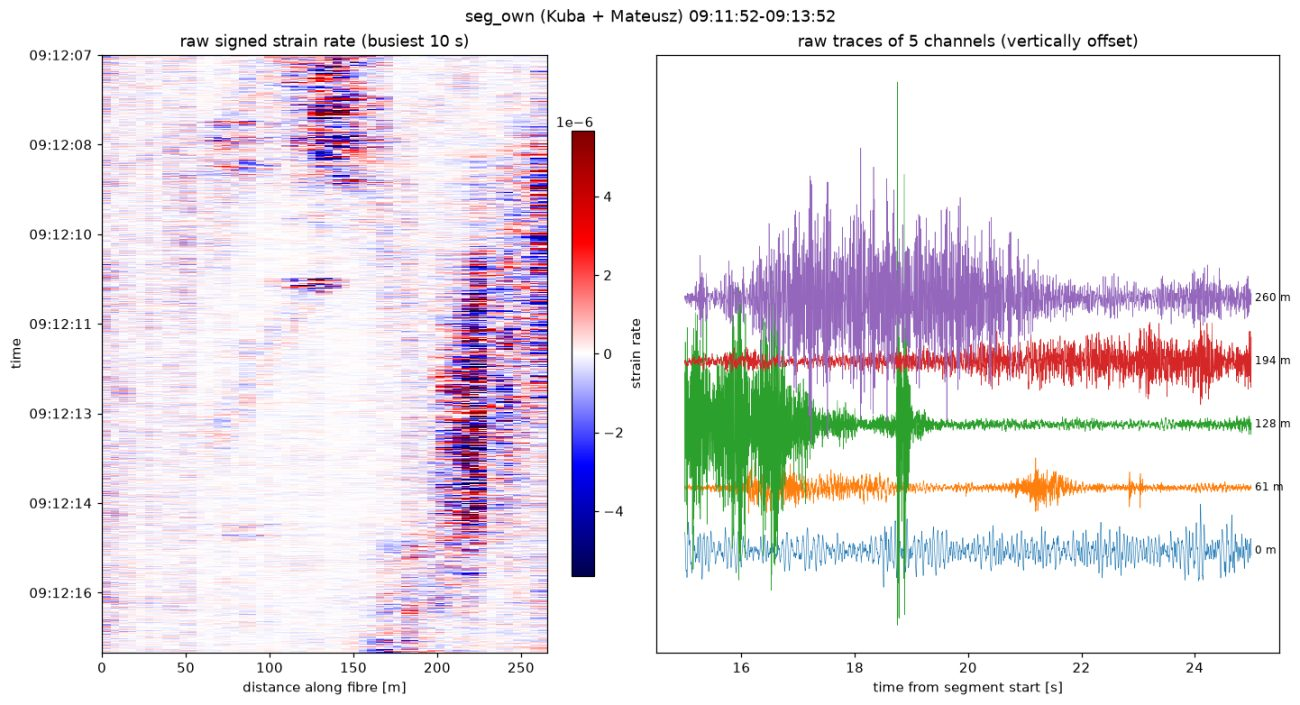

In [8]:
fig("eda_seg_kuba_waterfall")
fig("eda_seg_own_raw_zoom")

**What the data analysis means for the method.**
1. Heavy tails → robust statistics (median, MAD) everywhere, log compression, thresholds as
   multiples of the robust σ.
2. Exact zeros → a tiny constant is added before every logarithm and division.
3. The lines are visible only in the **energy** and on a **log scale** → RMS envelope +
   log10(envelope / channel median).
4. Traffic in both directions with crossings → the two directions are processed separately.
5. Busy and quiet periods → every threshold is computed from the image itself.

## 3. Frequency analysis

All spectra use the NumPy FFT. **The FFT is applied independently to every channel**: each
column of the time × channel matrix is windowed (Hann) and transformed along time; all channels
are transformed at once, without a loop.

Welch PSD of all files (median and spread over the channels) and the FFT amplitude of every
channel of seg_kuba:

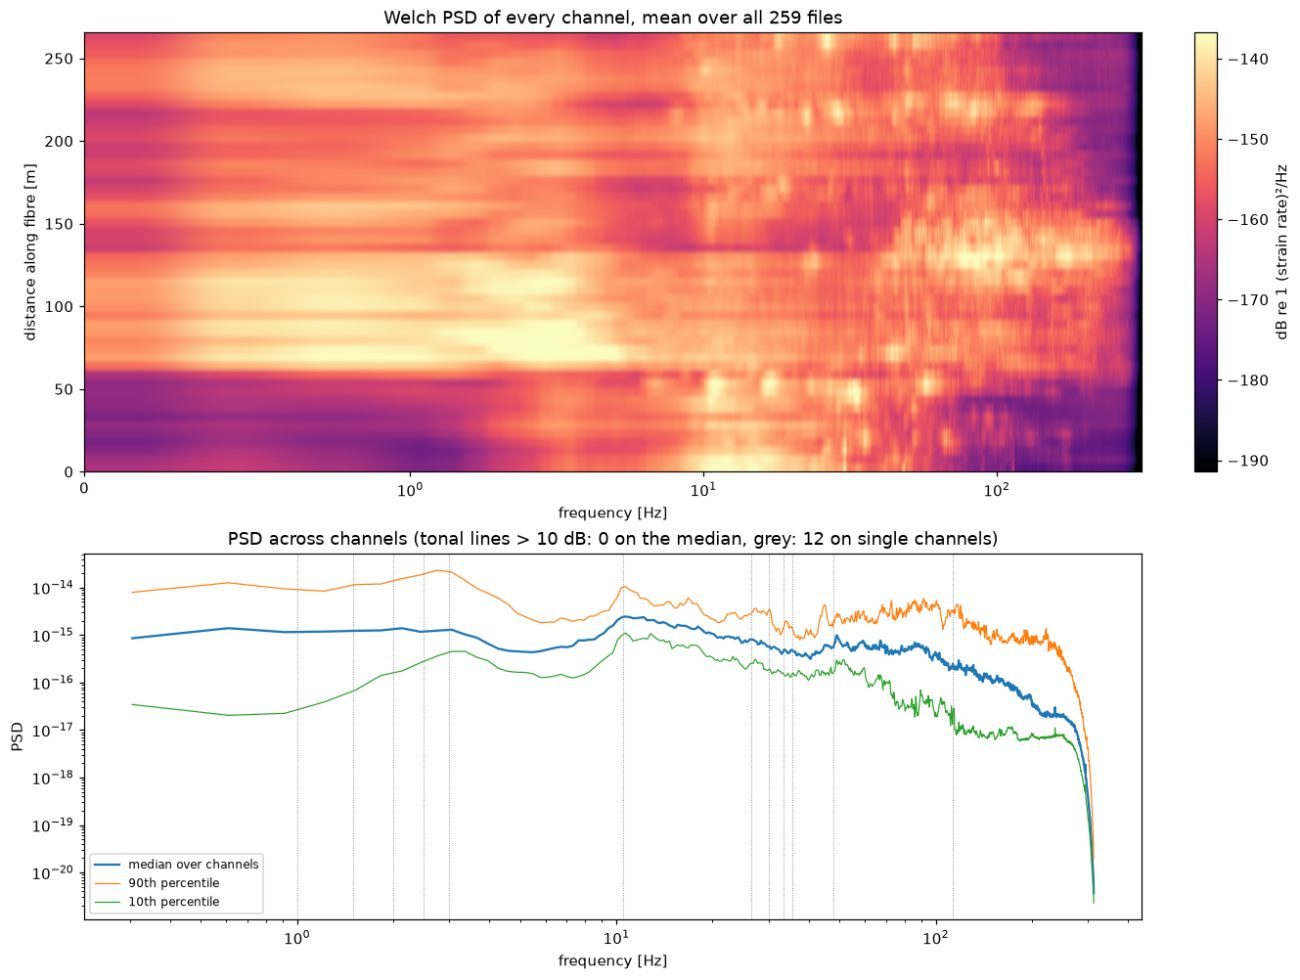

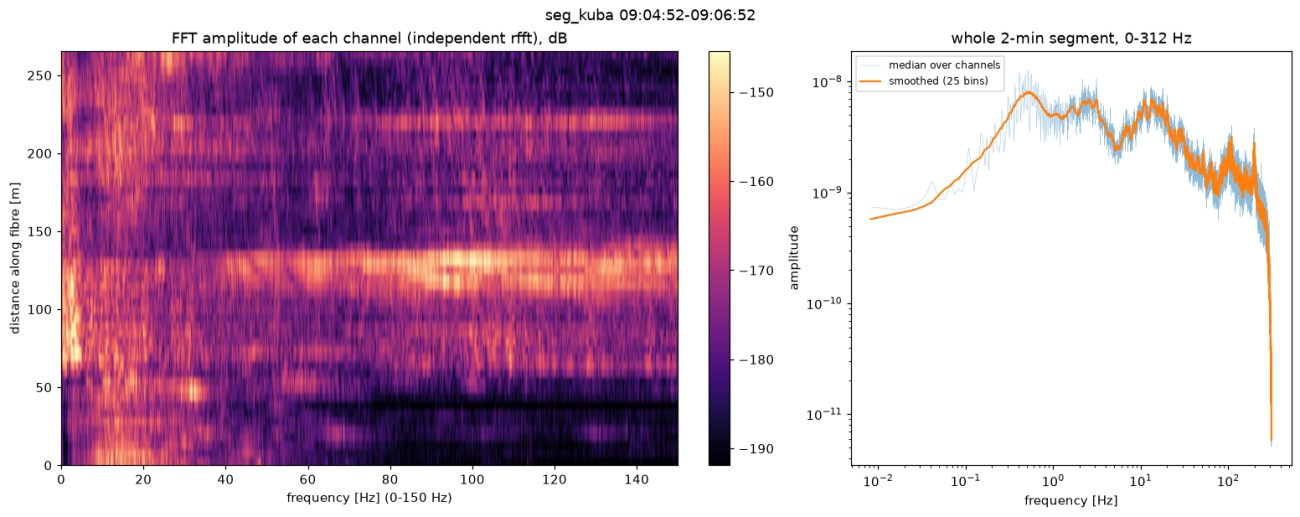

In [10]:
fig("spectral_global_psd")
fig("spectral_seg_kuba_fft")

**Time-frequency analysis (STFT)** of three channels (1 s Hann windows, 75 % overlap): trams are
broadband (20-150 Hz) for several seconds, the hotspot at 128 m gives short broadband impulses,
and weak stationary tones exist only on single channels. No tone rises more than 10 dB above the
background on the median spectrum (no 50 Hz mains), so **no notch filter is needed**.

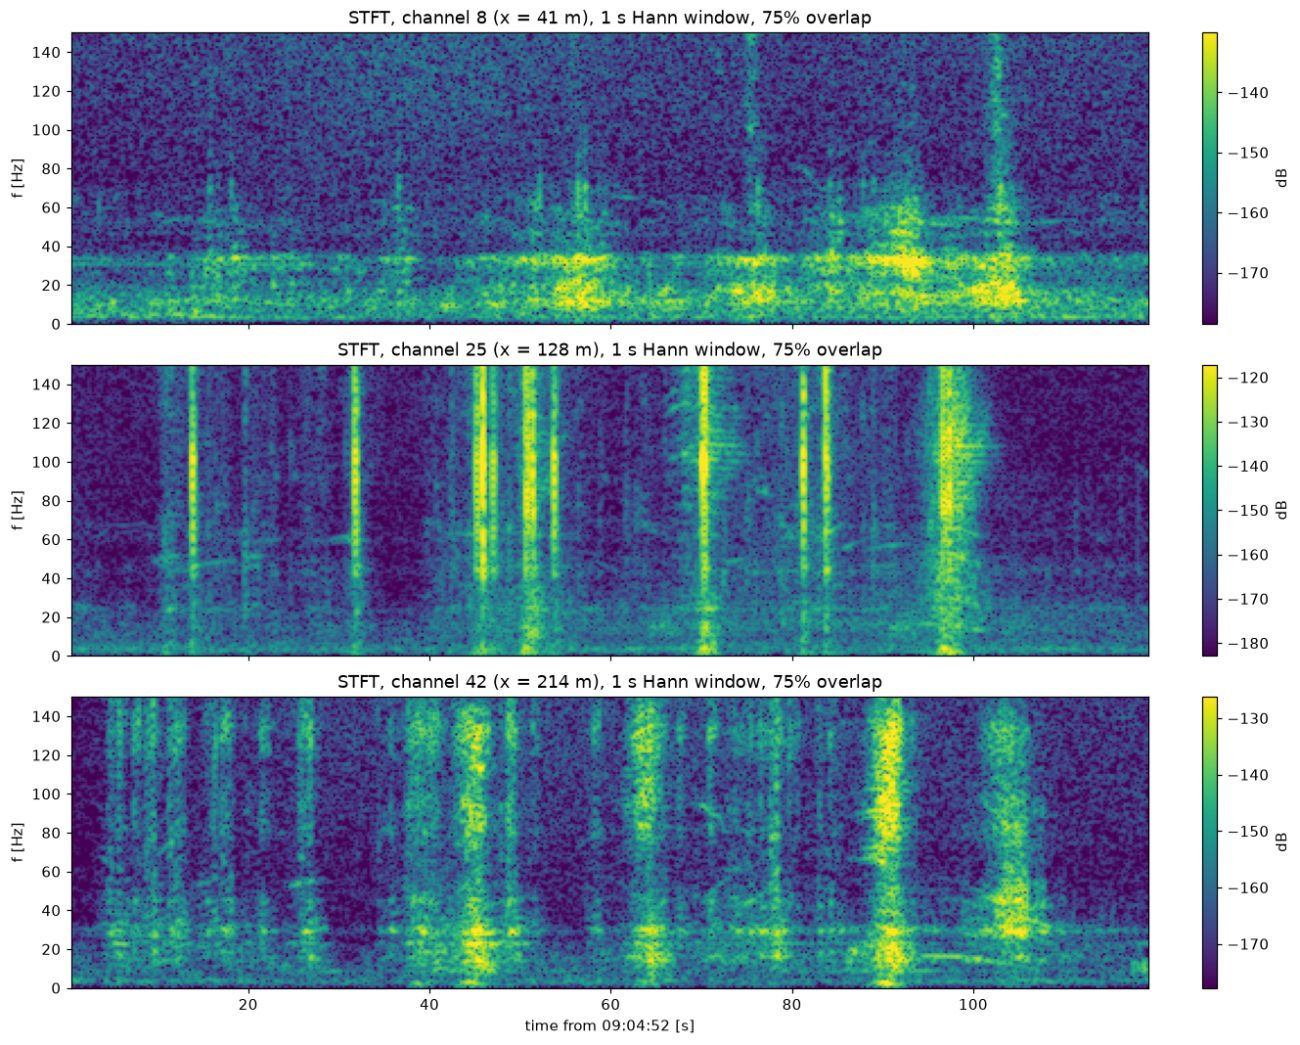

In [11]:
fig("spectral_seg_kuba_stft")

**f-k spectra** (2-D FFT over time and space) with ±20 / 50 / 100 km/h lines. A pattern moving
with velocity v lies on the line $f = -v\,k$, so every (f, k) cell has an apparent velocity
$v = -f/k$. In the energy envelopes the energy concentrates inside the "vehicle fan"; this is
the basis of the f-k filter in section 6.

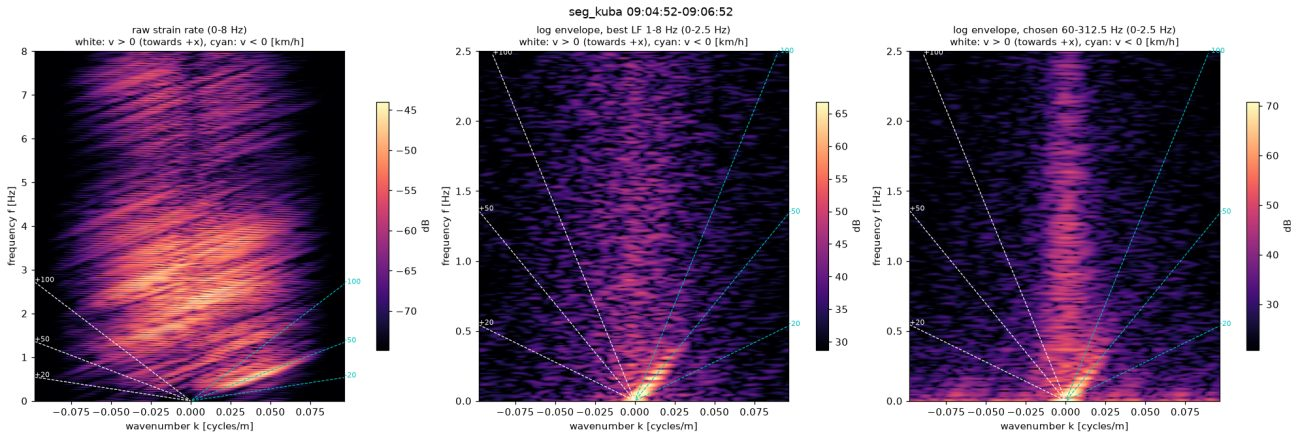

In [12]:
fig("spectral_seg_kuba_fk")

**Choice of the pass band.** For a grid of 16 × 19 bands, each segment is pre-processed with that
band and f-k filtered, and the **line SNR** (99th percentile of the robust z-score) is measured.
It rewards bands in which moving lines stand out from the background and needs no labels.

| band | line SNR |
|---|---|
| **60-312.5 Hz (chosen, best of the grid)** | **5.84** |
| 1-8 Hz (best low-frequency band) | 5.39 |
| broadband 0.2-312.5 Hz | 4.88 |

Visually (second figure), 60-312.5 Hz has a clean background and shows every thick line; 1-8 Hz
gives sharp lines but is blind for x < 55 m and misses some lanes.

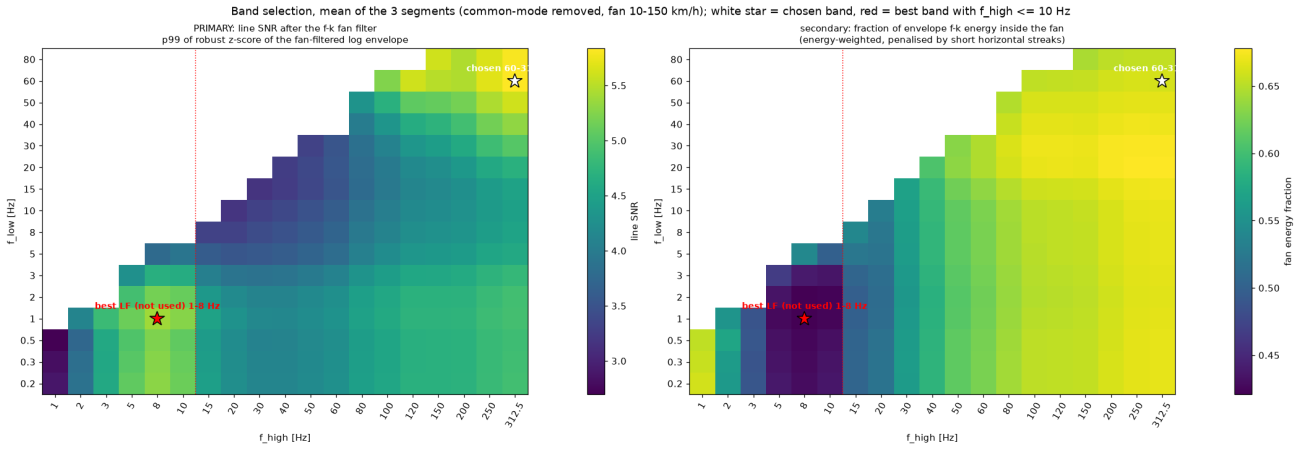

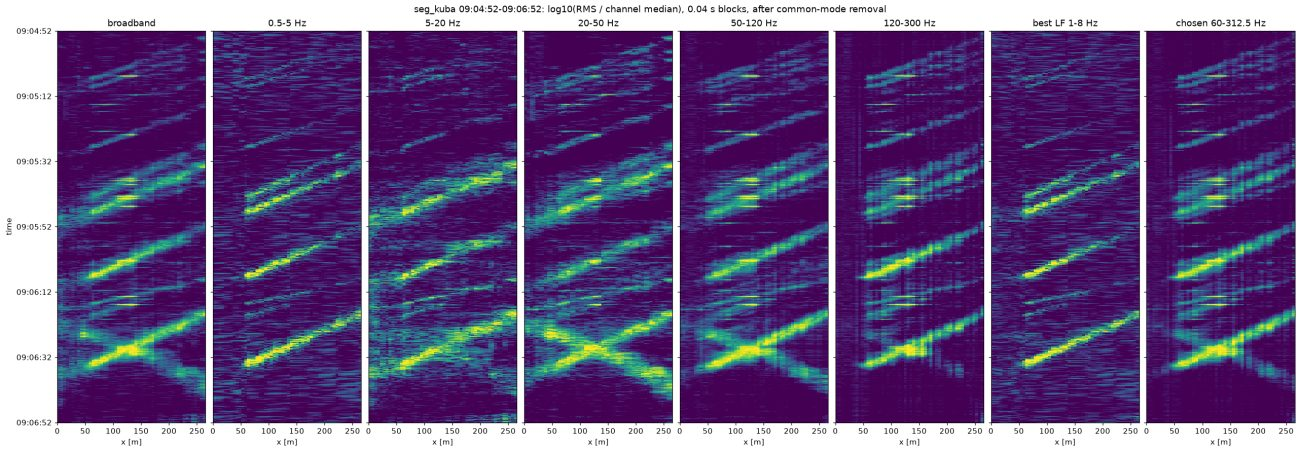

In [13]:
fig("spectral_band_selection")
fig("spectral_seg_kuba_band_comparison")

## 4. Algorithm overview (block diagram)

Every block notes what it removes (red). "Stage N" is the processing stage in our code (one
module per stage).

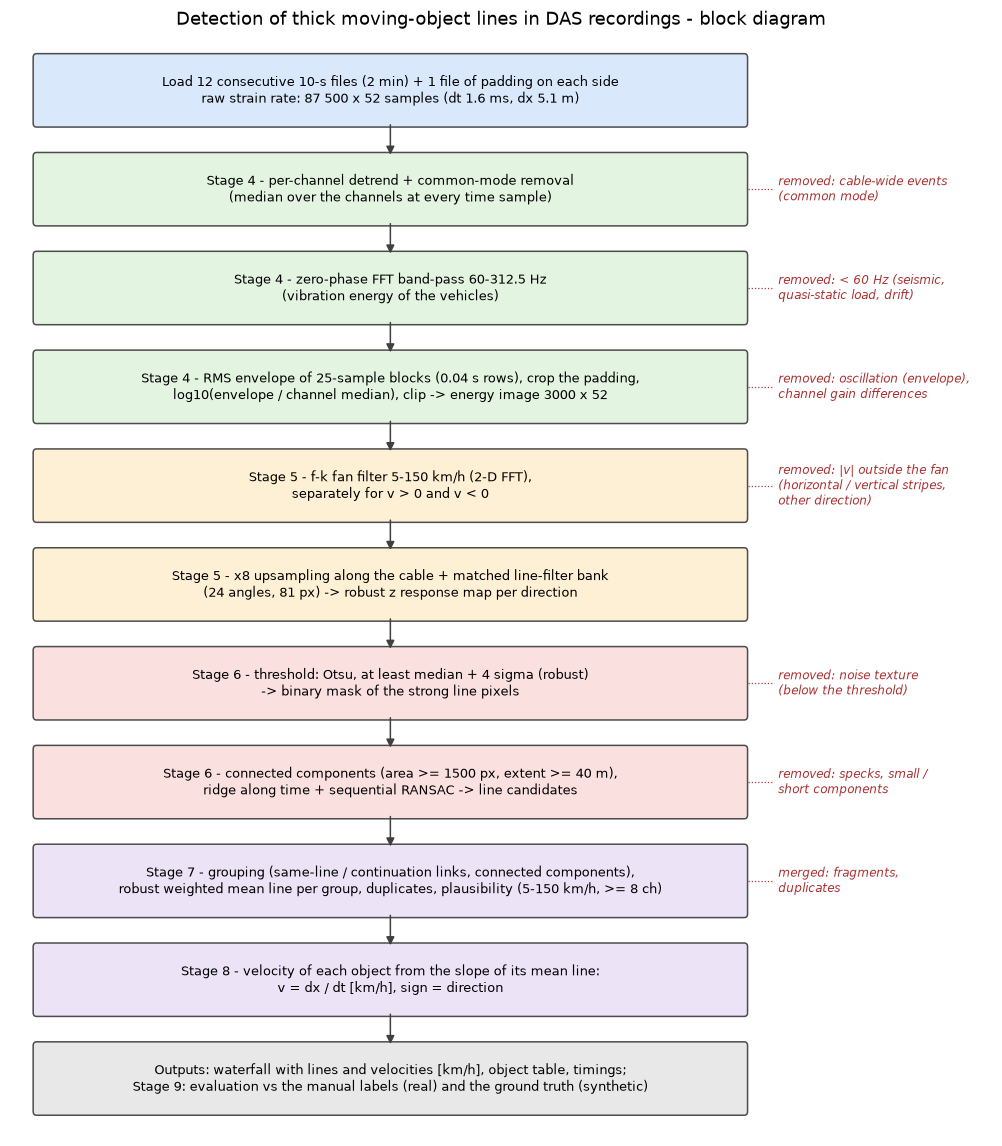

In [14]:
fig("flowchart", width=820)

| Block | What it does | Why |
|---|---|---|
| **Load** | 12 consecutive files + 1 file of padding on each side | continuous 2-minute segment; the padding keeps FFT edge effects outside |
| **Detrend + common mode** | subtract the trend of every channel and the median over channels at every sample | removes drift and events the whole cable sees at once (horizontal stripes) |
| **Band-pass 60-312.5 Hz** | zero-phase FFT filter | keeps the vibration energy of the vehicles (best line SNR) |
| **RMS envelope** | RMS of 25-sample blocks → 0.04 s rows | the lines exist only in the energy |
| **log10(env / channel median)** | gain equalisation + log compression | heavy tails; channel sensitivities differ |
| **f-k fan filter** | keep 5 ≤ \|v\| ≤ 150 km/h, separately for v > 0 and v < 0 | only moving objects remain; directions are separated |
| **Line-filter bank** | ×8 upsampling along the cable, 24 line kernels, maximum over angles → robust z | integrates the energy along lines, raises the line-to-noise ratio |
| **Threshold** | Otsu, at least median + 4σ | data-driven binary mask |
| **Components + RANSAC** | components ≥ 1500 px and ≥ 40 m; ridge + sequential RANSAC | one robust line per vehicle, also for touching trams |
| **Grouping** | link candidates of one vehicle, robust mean line | one averaged line per vehicle |
| **Velocity** | v = 1 / slope of the mean line | the slope of the line is the velocity |

## 5. Pre-processing: noise removal and the energy image

1. **Detrend + common-mode removal.** The mean and linear trend of every channel are removed.
   Then the **median over the channels** is subtracted at every time sample. An event that the
   whole fibre sees at once is in the median and disappears; a vehicle occupies only a few
   channels, so it survives.
2. **Zero-phase band-pass 60-312.5 Hz.** Real FFT of every channel, multiplication by a real
   frequency response with smooth (raised-cosine) edges, inverse FFT. A real response causes no
   phase shift, so the lines are not moved in time.
3. **Energy envelope and downsampling.** RMS of blocks of 25 samples,
   $e[r, c] = \sqrt{\tfrac{1}{25}\sum_{k} x[25r + k, c]^2}$ → one row per 0.04 s (3000 rows per
   2 minutes). Plain decimation without the RMS would alias the oscillating signal.
4. **Normalisation.**
   $I = \operatorname{clip}\big(\log_{10}(e / \operatorname{median}_{\text{channel}}\, e),\ 0,\ p_{99.5}\big)$:
   dividing by the channel median equalises the channels, the logarithm compresses the dynamic
   range so that a tram does not dominate, and clipping at 0 removes the below-typical background.

**Steps 2-3 on one channel** of seg_kuba (left: band-pass response; right: raw, band-passed and
envelope):

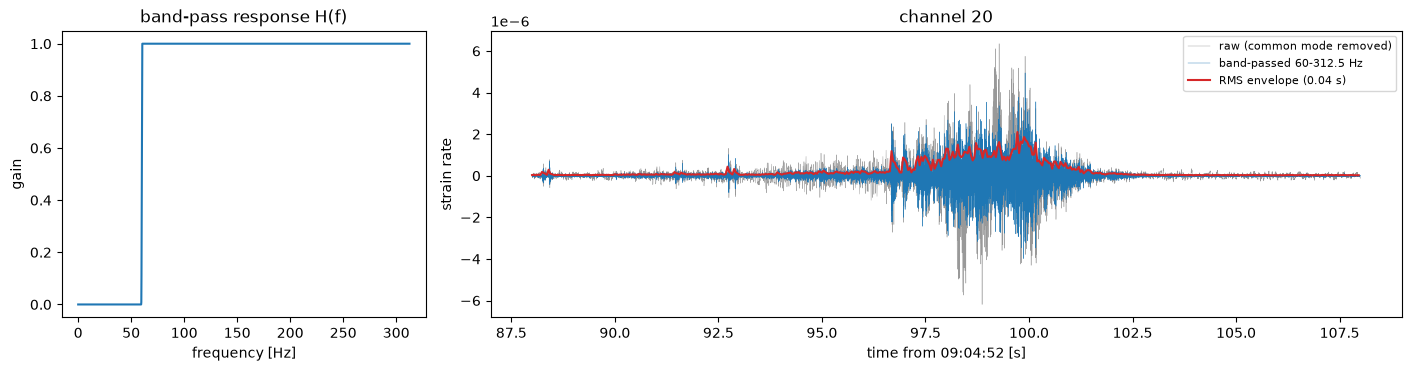

In [15]:
import matplotlib.pyplot as plt  # noqa: E402

from das import io as dio  # noqa: E402
from das import preprocessing as pre  # noqa: E402
from das.config import PreprocessingParams  # noqa: E402

pp = PreprocessingParams()
seg = dio.load_named_segment("seg_kuba", pad_files=1)
x = pre.remove_common_mode(pre.detrend_channels(seg.data))
xb = pre.bandpass_fft(x, 1 / seg.dt, pp.band_low, pp.band_high, pp.taper_hz)
env = pre.envelope_downsample(xb, pp.time_decimation)
c, t_a, t_b = 20, seg.pad_before + int(88 / seg.dt), seg.pad_before + int(108 / seg.dt)
t = np.arange(t_a, t_b) * seg.dt - seg.pad_before * seg.dt
fr = np.linspace(0, 312.5, 2000)
fig_, ax = plt.subplots(1, 2, figsize=(14, 3.6), layout="constrained",
                        gridspec_kw={"width_ratios": [1, 2.5]})
ax[0].plot(fr, pre.bandpass_response(fr, pp.band_low, pp.band_high, pp.taper_hz))
ax[0].set(xlabel="frequency [Hz]", ylabel="gain", title="band-pass response H(f)")
ax[1].plot(t, x[t_a:t_b, c], lw=0.3, color="0.6", label="raw (common mode removed)")
ax[1].plot(t, xb[t_a:t_b, c], lw=0.3, color="tab:blue", label="band-passed 60-312.5 Hz")
r = np.arange(t_a // 25, t_b // 25)
ax[1].plot(r * 25 * seg.dt - seg.pad_before * seg.dt, env[r, c], color="tab:red", lw=1.5,
           label="RMS envelope (0.04 s)")
ax[1].set(xlabel="time from 09:04:52 [s]", ylabel="strain rate", title=f"channel {c}")
ax[1].legend(fontsize=8, loc="upper right")
plt.show()

**All pre-processing steps on seg_kuba**, with what each step removed: the common mode
(cable-wide horizontal stripes), the out-of-band part (low-frequency drift and seismic waves with
their vertical stripes) and finally the normalised image.

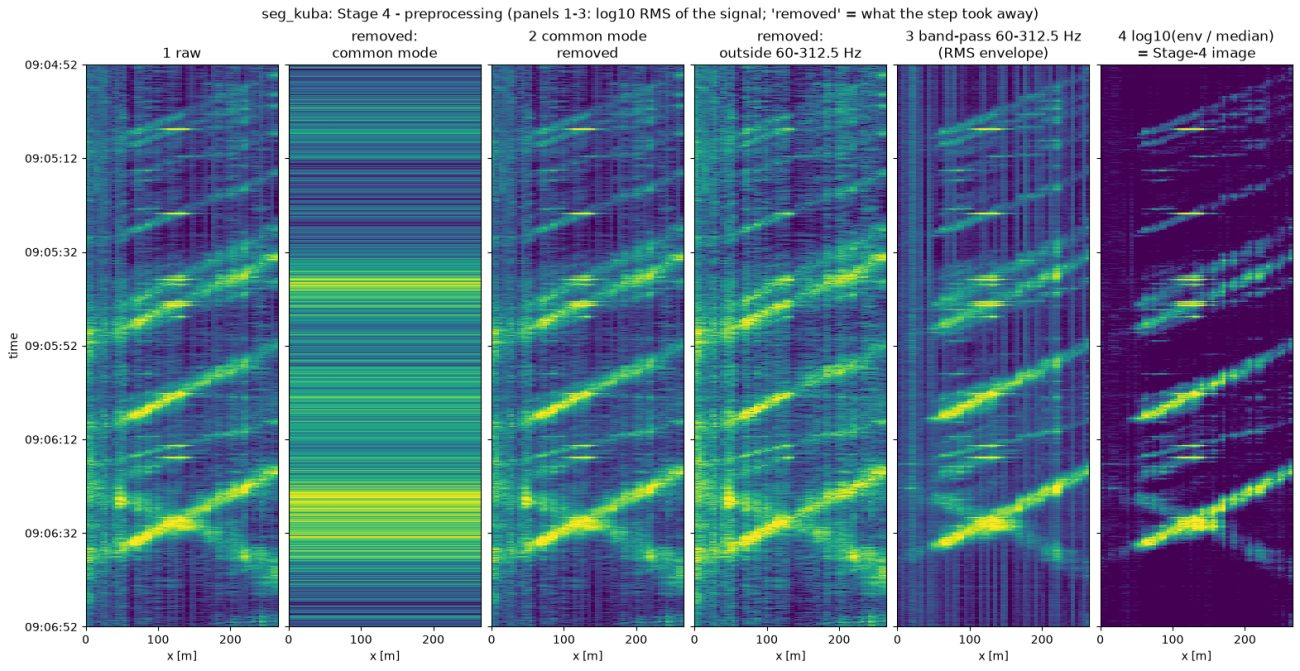

In [16]:
fig("step_seg_kuba_preprocessing")

## 6. Only moving objects: f-k fan filter and matched line filters

**f-k fan filter.** The image is transformed with a 2-D FFT into the frequency-wavenumber plane.
Every cell has an apparent velocity $v = -f/k$; the filter keeps the cells with
$5 \le |v| \le 150$ km/h (with smooth edges), **separately for v > 0 and v < 0**, and transforms
back. This removes horizontal structures (events seen by the whole cable at once), vertical
structures (static channel noise), the short dashes of the hotspot and the traffic of the other
direction.

**Matched line-filter bank.**
1. The filtered image is interpolated ×8 along the cable. With only 52 columns a line at 50 km/h
   would be almost vertical and its angle could not be resolved.
2. 24 line kernels per direction (81 px long, Gaussian cross-section) cover the slopes of
   5-150 km/h. Each kernel is zero-mean ("line minus surroundings").
3. The image is correlated with every kernel (OpenCV `filter2D`), the maximum over the angles is
   kept and converted to a robust z-score.

Left: the fan mask (white = kept) for v < 0. Right: three of the 24 kernels.

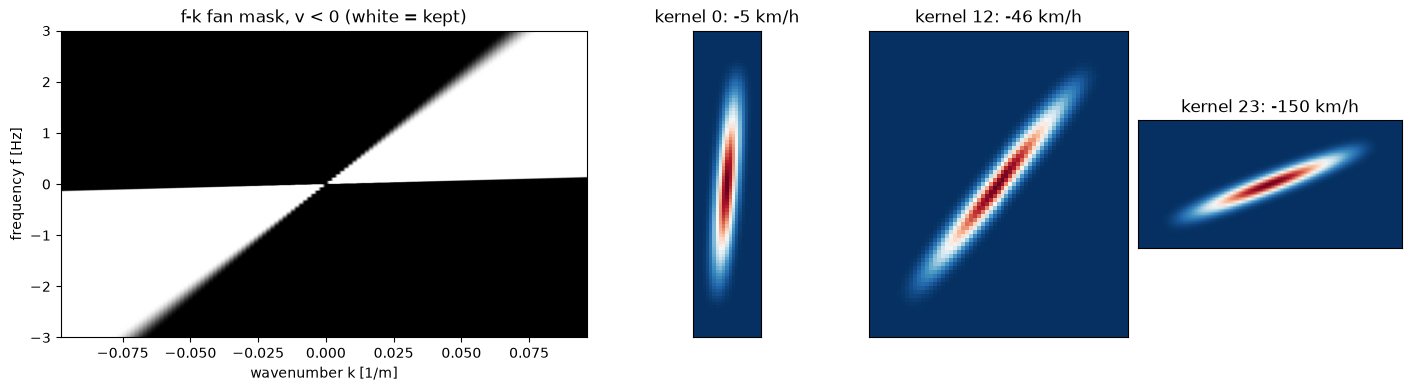

In [17]:
from das import enhancement as enh  # noqa: E402
from das.config import EnhancementParams  # noqa: E402

ep, row_dt, col_dx = EnhancementParams(), 0.04, config.DX
f_ax, k_ax = np.fft.fftshift(np.fft.fftfreq(3000, row_dt)), np.fft.fftshift(np.fft.fftfreq(128, col_dx))
mask = enh.fk_fan_mask(f_ax, k_ax, ep.v_min_kmh / 3.6, ep.v_max_kmh / 3.6, -1, ep.fk_taper)
angles = enh.bank_angles(ep.v_min_kmh / 3.6, ep.v_max_kmh / 3.6, -1, ep.n_angles, row_dt,
                         col_dx / ep.space_upsample)
kernels = enh.oriented_line_kernels(ep.kernel_length_px, angles, ep.kernel_width_sigma)
fig_, ax = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained",
                        gridspec_kw={"width_ratios": [2, 1, 1, 1]})
ax[0].imshow(mask, aspect="auto", origin="lower", cmap="gray",
             extent=(k_ax[0], k_ax[-1], f_ax[0], f_ax[-1]))
ax[0].set(ylim=(-3, 3), xlabel="wavenumber k [1/m]", ylabel="frequency f [Hz]",
          title="f-k fan mask, v < 0 (white = kept)")
for a, i in zip(ax[1:], (0, 12, 23)):
    a.imshow(kernels[i], cmap="RdBu_r")
    v = np.tan(angles[i]) * col_dx / ep.space_upsample / row_dt * 3.6
    a.set(title=f"kernel {i}: {v:.0f} km/h", xticks=[], yticks=[])
plt.show()

**On seg_kuba**: the input image, the f-k filtered image and **what the fan removed**, the image
of each direction, and the final response maps. The tram towards +x at 09:06:20-09:06:45, which
crosses the dominant traffic, appears only in the v > 0 map.

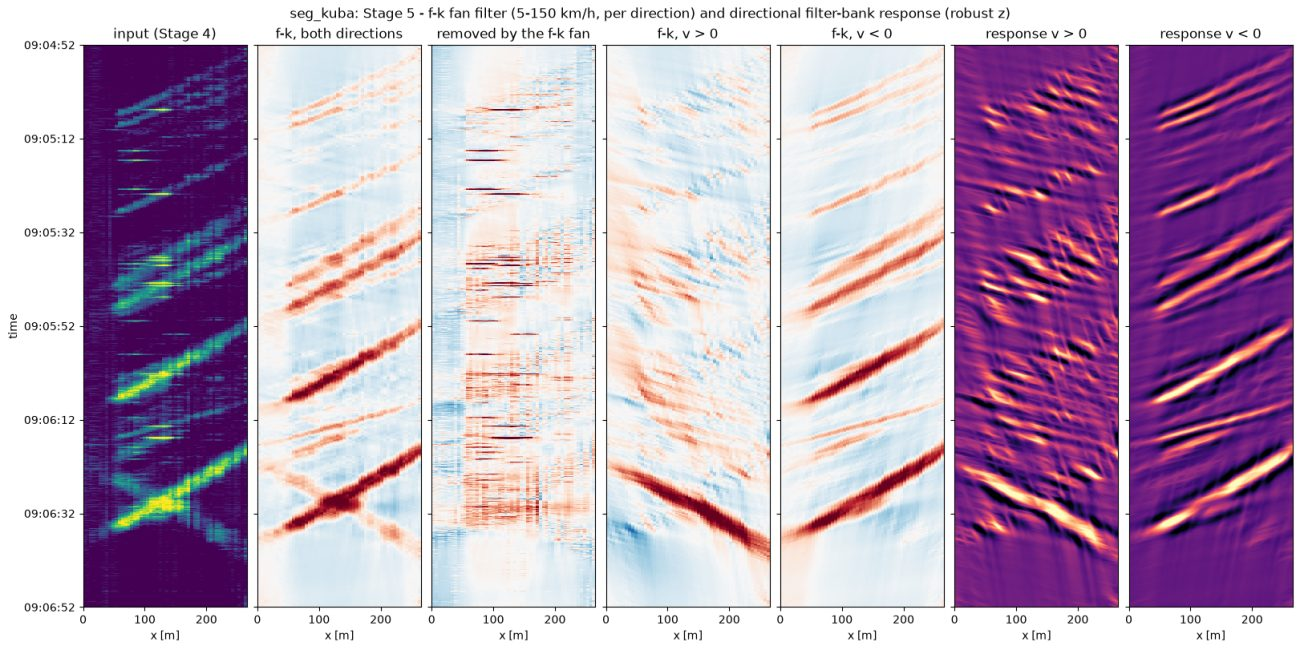

In [18]:
fig("step_seg_kuba_enhancement")

## 7. Detection of the thick lines

Each direction's response map is processed separately.

1. **Threshold.** Otsu's threshold of the response, but at least median + 4σ (robust σ). The
   floor matters in a direction with little heavy traffic, where Otsu would only split the noise
   texture. 4σ and not more, so that wide, diffuse tram lines (z ≈ 4-6) are kept.
2. **Connected components** (scikit-image). A component is kept if its area is ≥ 1500 px and it
   spans ≥ 40 m of cable; this removes specks and short blobs.
3. **Ridge + sequential RANSAC.** In every component the ridge is taken: the pixels that are
   maxima of the response within ±0.2 s along time, i.e. the centre of the line. Two trams that
   touch in the mask still give two ridges. The ridge points are fitted with RANSAC (robust to
   outliers); the inliers are removed and the fit is repeated (≤ 4 lines per component).

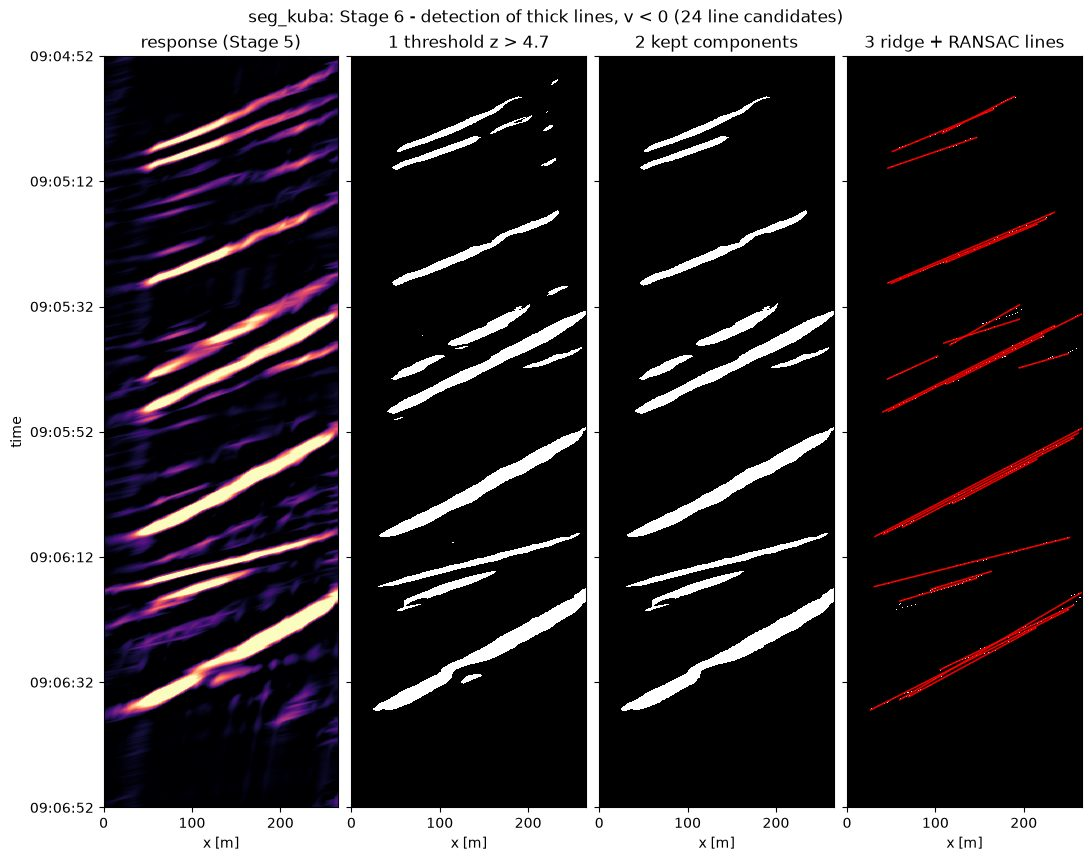

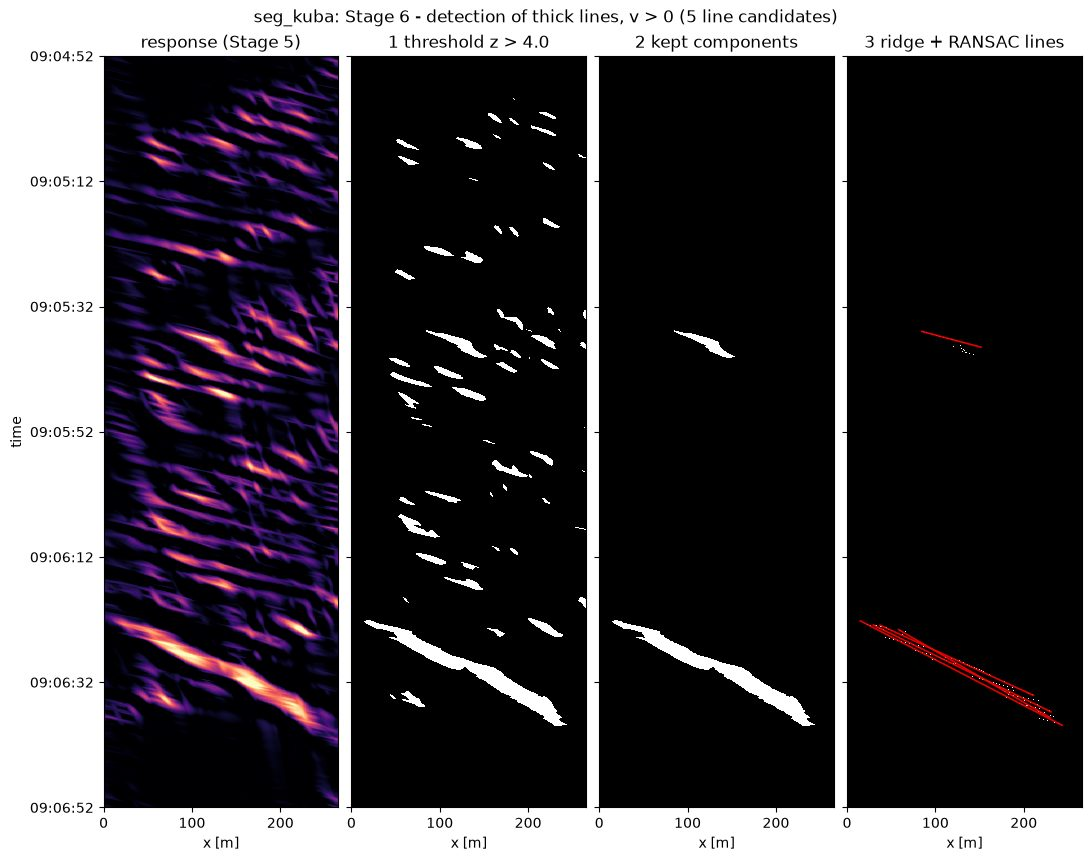

In [19]:
fig("step_seg_kuba_detection_neg")
fig("step_seg_kuba_detection_pos")

## 8. Grouping and velocity

One vehicle can give several candidates: a line split where its response drops, the bent ends of a
line near the cable ends, or pieces along a wide line. As the brief suggests, we group them and
take the average line.

1. Each candidate becomes a line in physical units, $t(x) = t_c + p\,(x - x_c)$, with the slowness
   $p = dt/dx$.
2. Two candidates of the same direction are **linked** if they lie on the same line (similar
   velocity and < 1.5 s apart) or one continues the other along the cable.
3. **Groups** = connected sets of linked candidates. For each group a robust weighted
   least-squares fit gives one **mean line**.
4. Duplicates are merged; objects shorter than 8 channels or outside 5-150 km/h are dropped.

**Velocity.** A vehicle at velocity v covers 1 m in 1/v seconds, so
$$v = \frac{1}{p}\ \mathrm{[m/s]}, \qquad v\,[\mathrm{km/h}] = 3.6 / p .$$
v > 0 means movement towards increasing cable position. It is the mean velocity over the observed
part of the cable (≤ 266 m).

Candidates → groups (one colour per group) → one line per object, for seg_kuba and seg_own:

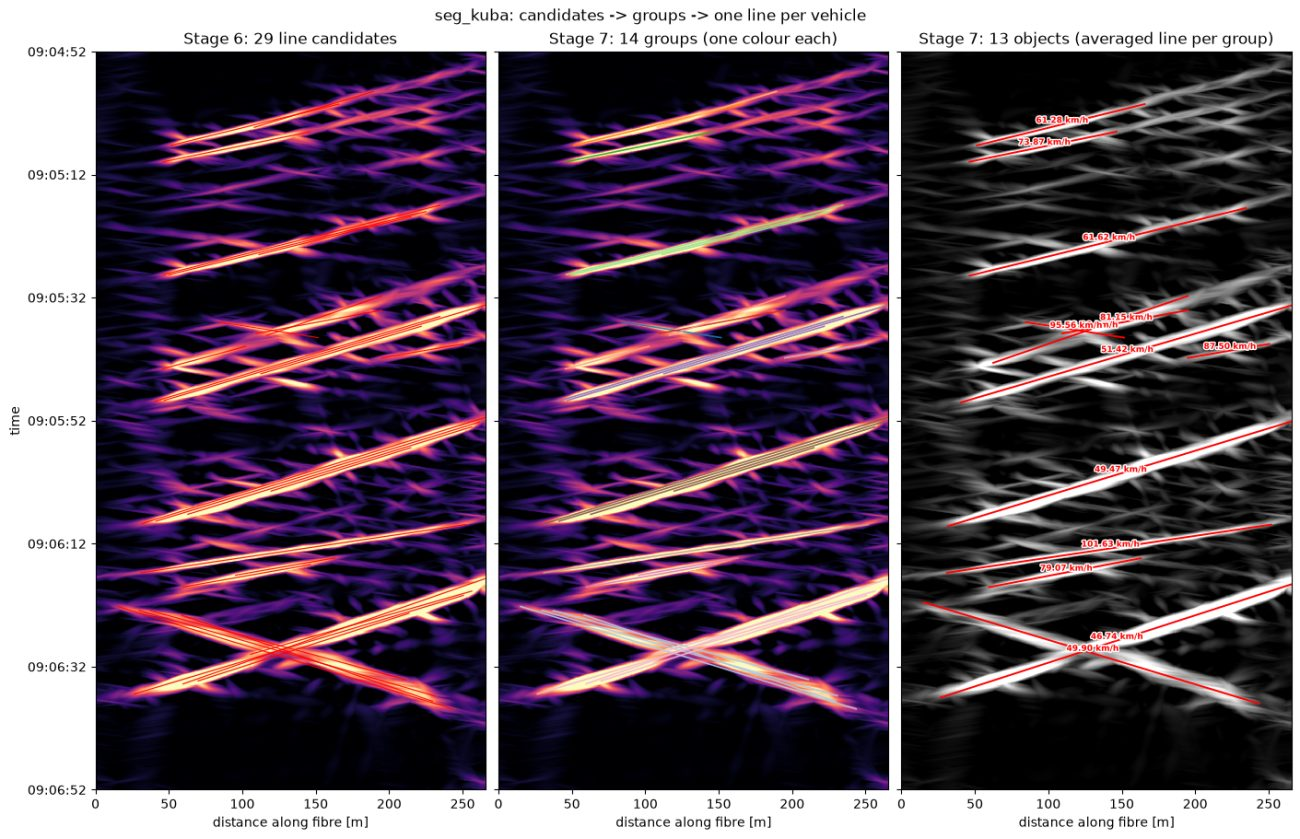

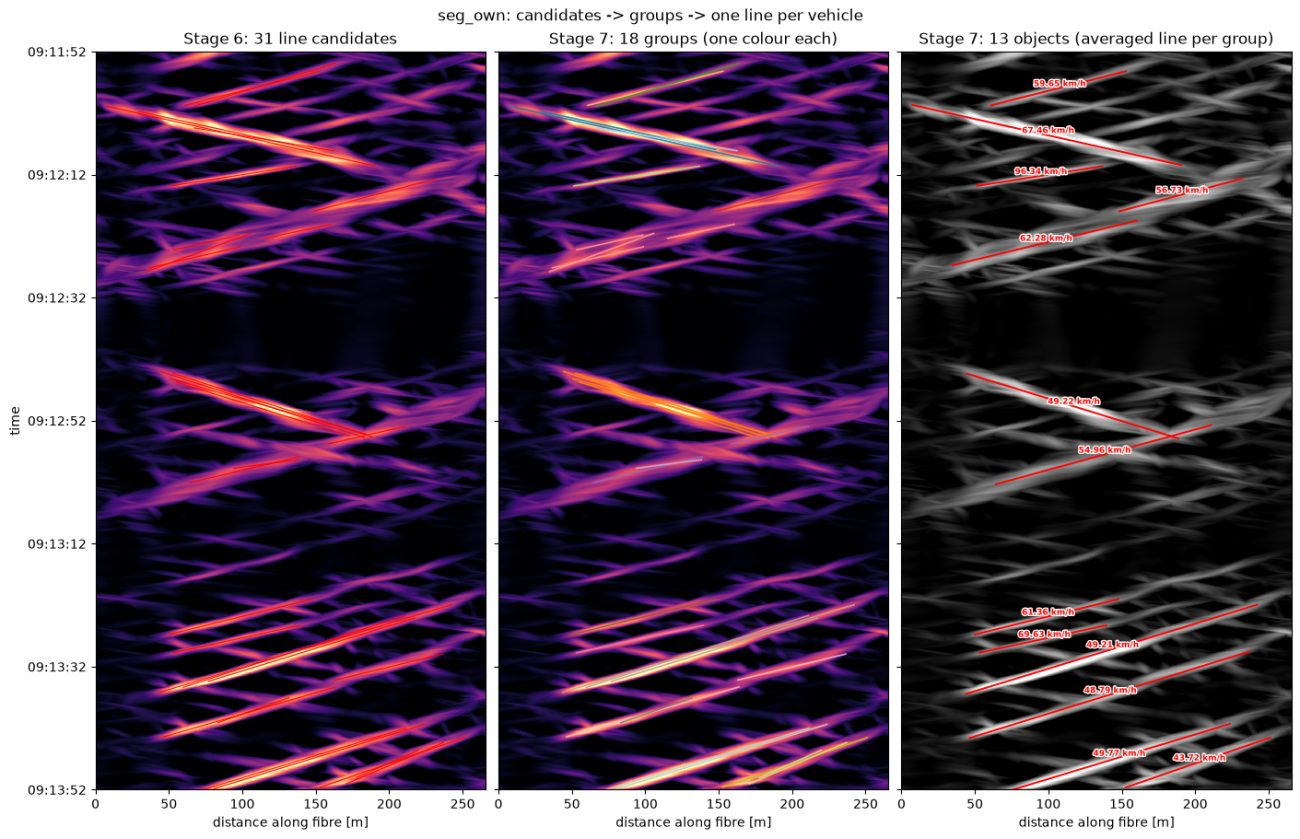

In [20]:
fig("step_seg_kuba_grouping")
fig("step_seg_own_grouping")

Example - the first object of seg_kuba:

In [21]:
o = read_csv("pipeline_seg_kuba_objects.csv")[0]
p = (float(o["t_end_s"]) - float(o["t_start_s"])) / (float(o["x_end_m"]) - float(o["x_start_m"]))
print(f"object 0: enters at x = {o['x_start_m']} m, t = {o['t_start_s']} s; leaves at "
      f"x = {o['x_end_m']} m, t = {o['t_end_s']} s")
print(f"slowness p = dt/dx = {p:.4f} s/m  ->  v = 3.6 / p = {3.6 / p:.2f} km/h "
      f"(table: {o['velocity_kmh']} km/h)")

object 0: enters at x = 165.6 m, t = 8.54 s; leaves at x = 51.4 m, t = 15.25 s
slowness p = dt/dx = -0.0588 s/m  ->  v = 3.6 / p = -61.27 km/h (table: -61.28 km/h)


## 9. Results for the three 2-minute segments

**Live run.** The whole pipeline runs here on seg_kuba from the raw files and is compared with the
saved batch result:

In [22]:
import time  # noqa: E402

from das.config import PipelineParams  # noqa: E402
from das.pipeline import run_segment  # noqa: E402

seg = dio.load_named_segment("seg_kuba", pad_files=1)
t = time.perf_counter()
res = run_segment(seg, PipelineParams())
elapsed = time.perf_counter() - t
c = res.counts
print(f"raw {seg.data.shape[0]} x {seg.data.shape[1]} -> image {res.pre.image.shape[0]} x "
      f"{res.pre.image.shape[1]} -> {c['n_objects']} objects ({c['n_pos']} with v > 0, "
      f"{c['n_neg']} with v < 0) in {elapsed:.1f} s")
saved = read_csv("pipeline_seg_kuba_objects.csv")
same = len(saved) == len(res.objects) and all(
    abs(float(r["velocity_kmh"]) - o.velocity_kmh) < 0.01 for r, o in zip(saved, res.objects))
print(f"identical to the saved batch result: {'yes' if same else 'NO'}")

raw 87500 x 52 -> image 3000 x 52 -> 13 objects (2 with v > 0, 11 with v < 0) in 1.2 s
identical to the saved batch result: yes


**Objects per direction and processing time per stage** (laptop CPU, one process):

In [23]:
table(SUMM, ["name", "start", "n_objects", "n_pos", "n_neg", "preprocess_s", "enhance_s",
             "detect_s", "group_s", "total_s", "realtime_factor"],
      ["segment", "start", "objects", "v > 0", "v < 0", "preprocess [s]", "enhance [s]",
       "detect [s]", "group [s]", "total [s]", "× real time"], nd=2)

| segment | start | objects | v > 0 | v < 0 | preprocess [s] | enhance [s] | detect [s] | group [s] | total [s] | × real time |
|---|---|---|---|---|---|---|---|---|---|---|
| seg_kuba | 09:04:52 | 13 | 2 | 11 | 0.20 | 0.77 | 0.21 | 0.00 | 1.18 | 101.90 |
| seg_mateusz | 09:32:22 | 17 | 4 | 13 | 0.23 | 0.84 | 0.15 | 0.00 | 1.23 | 97.48 |
| seg_own | 09:11:52 | 13 | 2 | 11 | 0.20 | 0.76 | 0.18 | 0.00 | 1.15 | 104.84 |

For every segment: the detected lines with their velocities on the raw waterfall (as in the
figure of the brief) and the object table. **t_ref** = clock time when the object passes the
middle of the cable; **score** = mean response on the line (robust z); **thickness** = mean width
of the line along time.

### 9.1 seg_kuba (assigned to Kuba, 09:04:52-09:06:52)

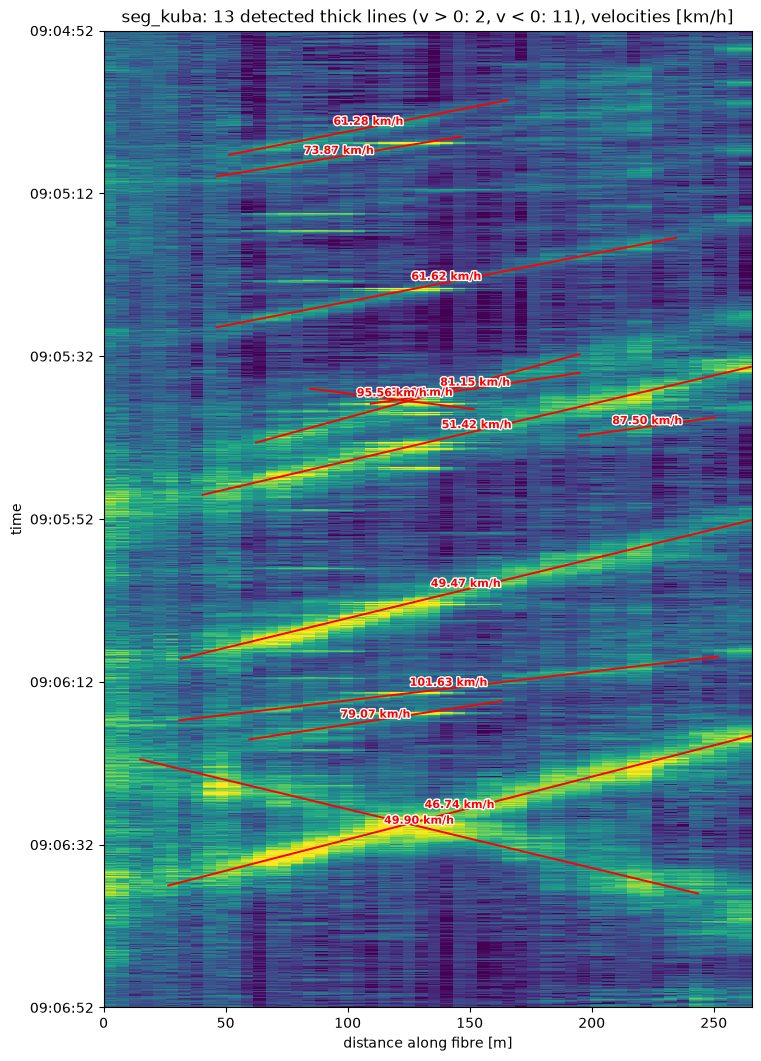

| id | dir | v [km/h] | t_ref | x start [m] | x end [m] | score | thickness [s] |
|---|---|---|---|---|---|---|---|
| 0 | -1 | -61.28 | 09:05:02.46 | 165.60 | 51.40 | 8.16 | 0.61 |
| 1 | -1 | -73.87 | 09:05:05.69 | 146.50 | 46.30 | 9.14 | 0.95 |
| 2 | -1 | -61.62 | 09:05:23.38 | 234.60 | 46.30 | 9.38 | 0.42 |
| 3 | -1 | -81.15 | 09:05:36.79 | 195.00 | 109.50 | 7.95 | 0.80 |
| 4 | -1 | -43.90 | 09:05:36.83 | 195.00 | 62.50 | 7.35 | 0.98 |
| 5 | 1 | 95.56 | 09:05:37.79 | 84.60 | 151.60 | 6.51 | 1.06 |
| 6 | -1 | -51.42 | 09:05:42.56 | 265.20 | 40.50 | 10.38 | 0.61 |
| 7 | -1 | -87.50 | 09:05:44.35 | 250.50 | 195.00 | 6.20 | 0.68 |
| 8 | -1 | -49.47 | 09:06:01.78 | 265.20 | 31.60 | 13.51 | 0.54 |
| 9 | -1 | -101.63 | 09:06:13.11 | 251.80 | 31.00 | 9.93 | 0.85 |
| 10 | -1 | -79.07 | 09:06:15.74 | 163.10 | 59.70 | 8.48 | 0.59 |
| 11 | -1 | -46.74 | 09:06:28.82 | 265.20 | 26.50 | 12.50 | 0.64 |
| 12 | 1 | 49.90 | 09:06:30.00 | 15.00 | 243.50 | 7.34 | 0.61 |

In [24]:
fig("result_seg_kuba_result", width=640)
table(read_csv("pipeline_seg_kuba_objects.csv"), ["id", "direction", "velocity_kmh", "t_ref_clock", "x_start_m", "x_end_m", "score", "thickness_s"],
      ["id", "dir", "v [km/h]", "t_ref", "x start [m]", "x end [m]", "score", "thickness [s]"], nd=2)

### 9.2 seg_mateusz (assigned to Mateusz, 09:32:22-09:34:22)

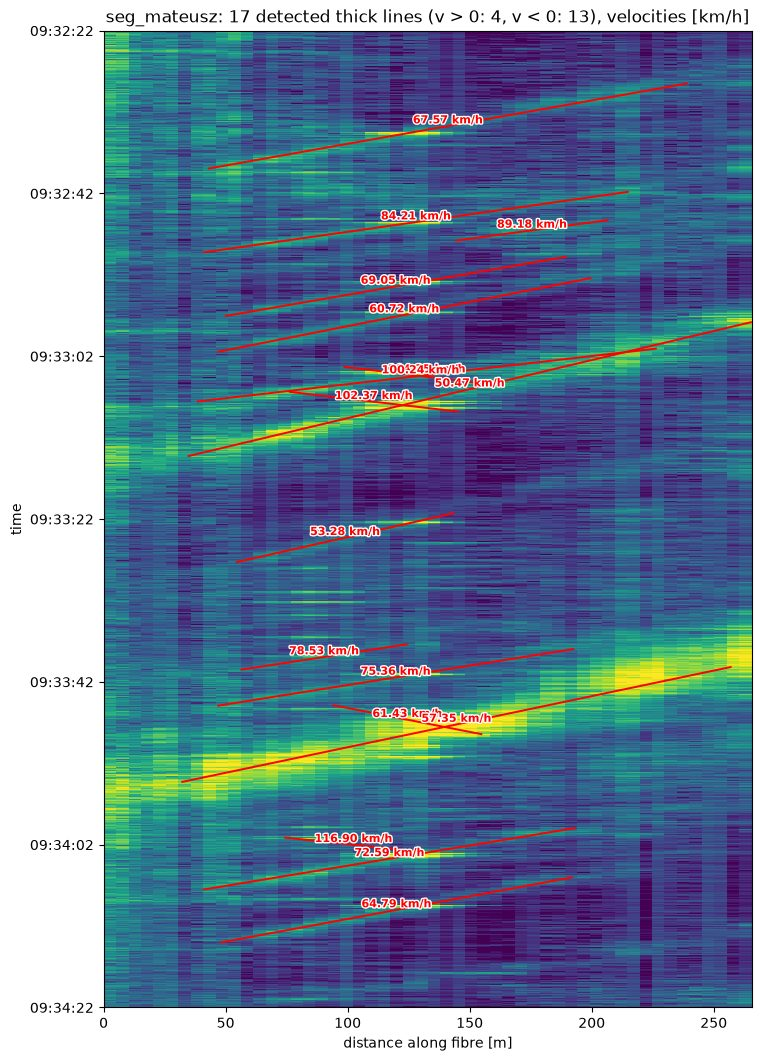

| id | dir | v [km/h] | t_ref | x start [m] | x end [m] | score | thickness [s] |
|---|---|---|---|---|---|---|---|
| 0 | -1 | -67.57 | 09:32:34.15 | 239.00 | 43.10 | 9.34 | 0.69 |
| 1 | -1 | -84.21 | 09:32:45.30 | 214.80 | 41.20 | 9.67 | 0.72 |
| 2 | -1 | -89.18 | 09:32:48.25 | 206.50 | 144.60 | 5.23 | 0.64 |
| 3 | -1 | -69.05 | 09:32:52.73 | 189.30 | 50.10 | 6.52 | 0.80 |
| 4 | -1 | -60.72 | 09:32:56.35 | 199.50 | 46.90 | 8.14 | 1.10 |
| 5 | -1 | -104.25 | 09:33:04.29 | 226.30 | 38.60 | 10.36 | 0.80 |
| 6 | 1 | 100.24 | 09:33:04.52 | 98.60 | 161.20 | 5.31 | 0.68 |
| 7 | -1 | -50.47 | 09:33:07.26 | 265.20 | 34.80 | 9.99 | 0.66 |
| 8 | 1 | 102.37 | 09:33:08.35 | 76.30 | 145.20 | 5.92 | 0.80 |
| 9 | -1 | -53.28 | 09:33:21.99 | 143.30 | 54.60 | 5.77 | 0.91 |
| 10 | -1 | -78.53 | 09:33:36.99 | 124.20 | 56.50 | 6.16 | 0.61 |
| 11 | -1 | -75.36 | 09:33:40.82 | 192.50 | 46.90 | 7.36 | 0.94 |
| 12 | 1 | 61.43 | 09:33:47.13 | 94.20 | 154.80 | 5.96 | 0.59 |
| 13 | -1 | -57.35 | 09:33:47.97 | 256.90 | 32.20 | 6.98 | 0.63 |
| 14 | 1 | 116.90 | 09:34:02.93 | 74.40 | 130.50 | 5.28 | 0.57 |
| 15 | -1 | -72.59 | 09:34:02.95 | 193.10 | 41.20 | 9.07 | 1.23 |
| 16 | -1 | -64.79 | 09:34:09.30 | 191.80 | 48.20 | 7.99 | 1.06 |

In [25]:
fig("result_seg_mateusz_result", width=640)
table(read_csv("pipeline_seg_mateusz_objects.csv"), ["id", "direction", "velocity_kmh", "t_ref_clock", "x_start_m", "x_end_m", "score", "thickness_s"],
      ["id", "dir", "v [km/h]", "t_ref", "x start [m]", "x end [m]", "score", "thickness [s]"], nd=2)

### 9.3 seg_own (own segment, 09:11:52-09:13:52)

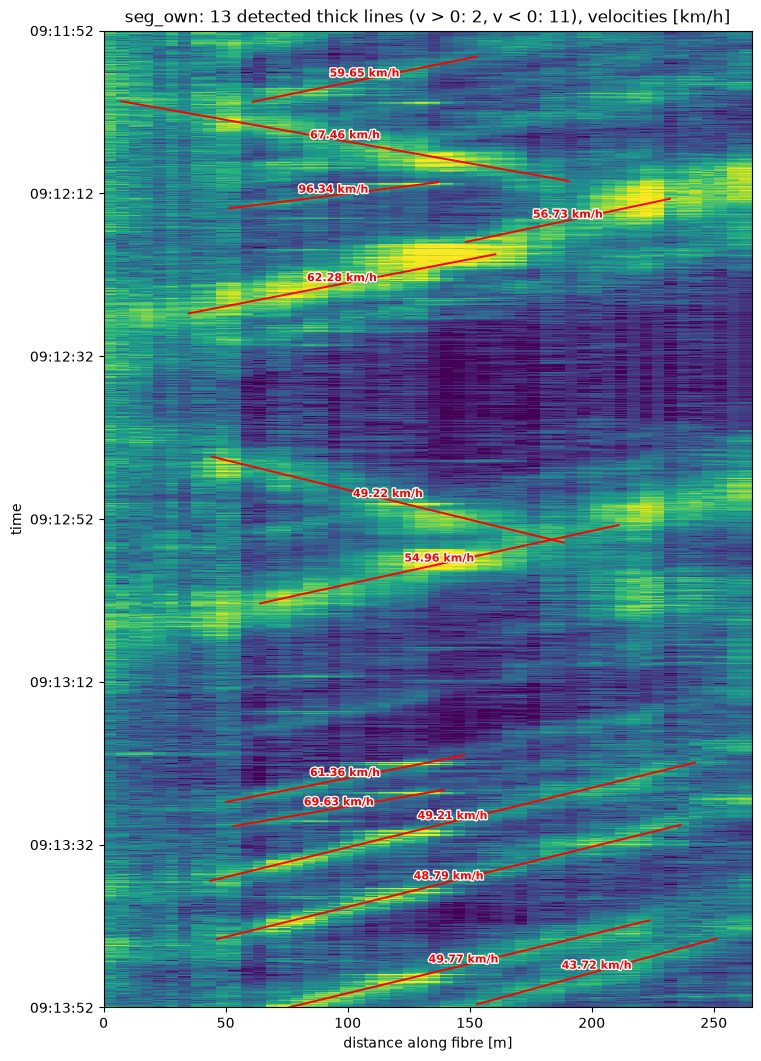

| id | dir | v [km/h] | t_ref | x start [m] | x end [m] | score | thickness [s] |
|---|---|---|---|---|---|---|---|
| 0 | -1 | -59.65 | 09:11:56.40 | 152.90 | 61.00 | 4.95 | 0.51 |
| 1 | 1 | 67.46 | 09:12:07.37 | 7.30 | 190.50 | 8.21 | 0.75 |
| 2 | -1 | -96.34 | 09:12:10.79 | 136.90 | 51.40 | 6.20 | 0.71 |
| 3 | -1 | -56.73 | 09:12:18.95 | 232.00 | 148.40 | 5.33 | 1.55 |
| 4 | -1 | -62.28 | 09:12:21.07 | 160.50 | 34.80 | 5.21 | 0.72 |
| 5 | 1 | 49.22 | 09:12:50.80 | 44.40 | 188.60 | 6.63 | 0.48 |
| 6 | -1 | -54.96 | 09:12:57.85 | 211.00 | 64.20 | 5.19 | 0.93 |
| 7 | -1 | -61.36 | 09:13:21.90 | 147.80 | 50.10 | 5.47 | 0.82 |
| 8 | -1 | -69.63 | 09:13:25.61 | 139.50 | 53.30 | 5.33 | 0.64 |
| 9 | -1 | -49.21 | 09:13:29.92 | 242.20 | 43.70 | 7.81 | 0.46 |
| 10 | -1 | -48.79 | 09:13:37.21 | 236.50 | 46.30 | 6.20 | 0.93 |
| 11 | -1 | -49.77 | 09:13:47.87 | 223.70 | 71.20 | 7.59 | 0.78 |
| 12 | -1 | -43.72 | 09:13:53.26 | 251.20 | 152.90 | 5.83 | 0.59 |

In [26]:
fig("result_seg_own_result", width=640)
table(read_csv("pipeline_seg_own_objects.csv"), ["id", "direction", "velocity_kmh", "t_ref_clock", "x_start_m", "x_end_m", "score", "thickness_s"],
      ["id", "dir", "v [km/h]", "t_ref", "x start [m]", "x end [m]", "score", "thickness [s]"], nd=2)

**Observations.**
- In all three segments most thick lines move towards decreasing x (v < 0); their lines are long
  and almost straight.
- seg_own is the busiest segment and has the most traffic towards +x; some lines are cut where
  they cross a stronger line of the other direction.
- Most velocities are 45-90 km/h, plausible for trams and trucks on a city artery. The few values
  above 100 km/h belong to short or crossing lines and are the least reliable.
- Most of the processing time is the enhancement (2 directions × 24 kernels on the ×8 grid).

## 10. Evaluation

**References.**
- *Real data* have no ground truth. Kuba marked every visible line of the three segments by hand
  with our labelling tool (Matplotlib) on the raw waterfall - never on the detector output - with
  a thick / thin label. Strokes with an implausible velocity or shorter than 30 m are not scored,
  leaving **47 labels (23 thick, 24 thin)**.
- *Synthetic data* (6 samples) have a ground-truth mask: 49 trams / trucks (thick) and 85 cars
  (thin). They are used only as a validation, because they are the only exact reference for the
  velocity.

**Matching and metrics.** Detections and references are matched one-to-one (same direction,
|Δt| < 1.5 s, |Δv| < 20 km/h).
- **thick recall** = found thick references / thick references (the main metric);
- **precision** = matched detections / detections. A loud car matched to a *thin* label is a real
  vehicle, not a false positive - the brief asks to detect the thick lines, not to classify;
- **F1** of the two, and the **velocity error** of the matched pairs.

### 10.1 Real segments vs the manual labels

In [27]:
table(read_csv("eval_real.csv")[:4],
      ["segment", "n_det", "n_ref_thick", "tp_thick", "recall_thick", "tp", "precision", "f1",
       "tp_thin", "fp_near_label", "fp_no_label", "vel_mae_thick"],
      ["segment", "detections", "thick labels", "thick found", "thick recall", "matched",
       "precision", "F1", "thin found", "FP near a label", "FP no label", "thick |v| diff [km/h]"])

| segment | detections | thick labels | thick found | thick recall | matched | precision | F1 | thin found | FP near a label | FP no label | thick \|v\| diff [km/h] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| seg_kuba | 13 | 8 | 8 | 1.000 | 10 | 0.769 | 0.870 | 2 | 2 | 1 | 1.384 |
| seg_mateusz | 17 | 4 | 4 | 1.000 | 12 | 0.706 | 0.828 | 8 | 4 | 1 | 3.206 |
| seg_own | 13 | 11 | 9 | 0.818 | 12 | 0.923 | 0.867 | 3 | 1 | 0 | 4.876 |
| ALL | 43 | 23 | 21 | 0.913 | 34 | 0.791 | 0.847 | 13 | 7 | 2 | 3.228 |

Detections (red = matched, orange = false positive near a label, magenta = no label) and labels
(lime = found, yellow = missed; solid = thick, dotted = thin; cyan = not scored):

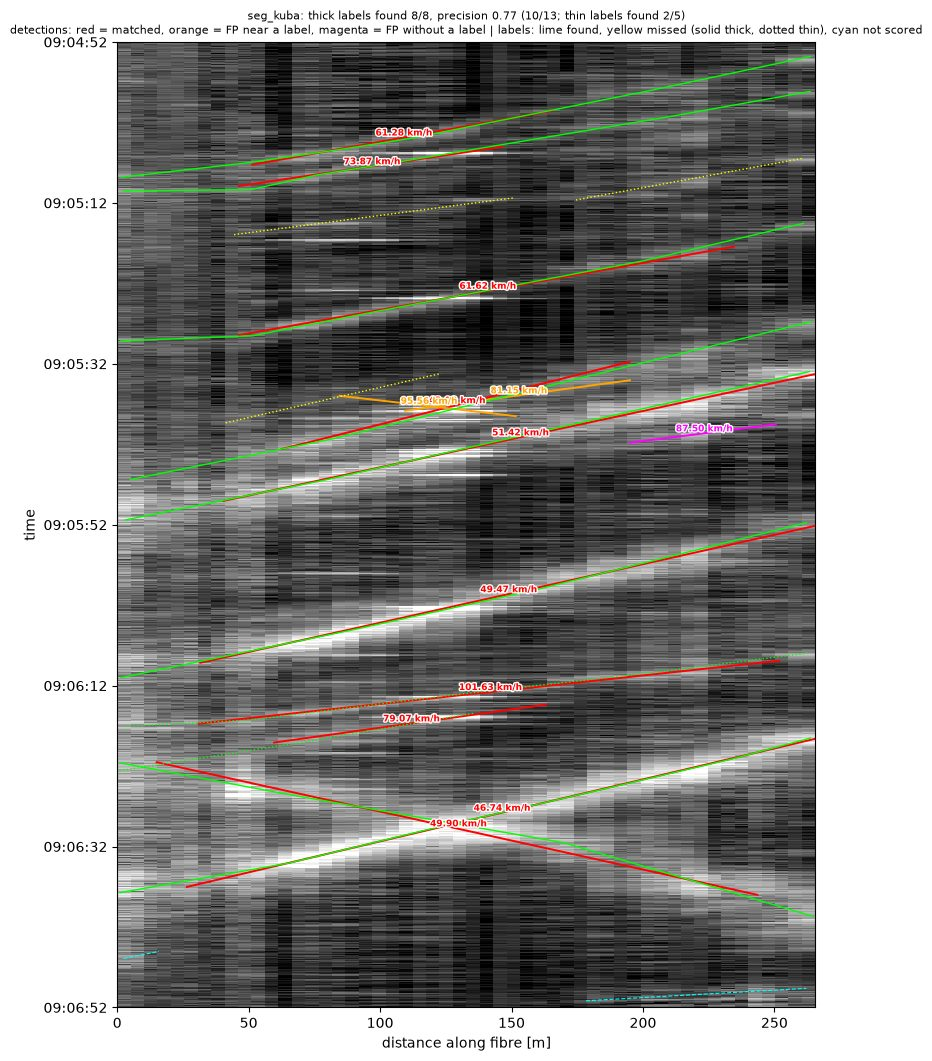

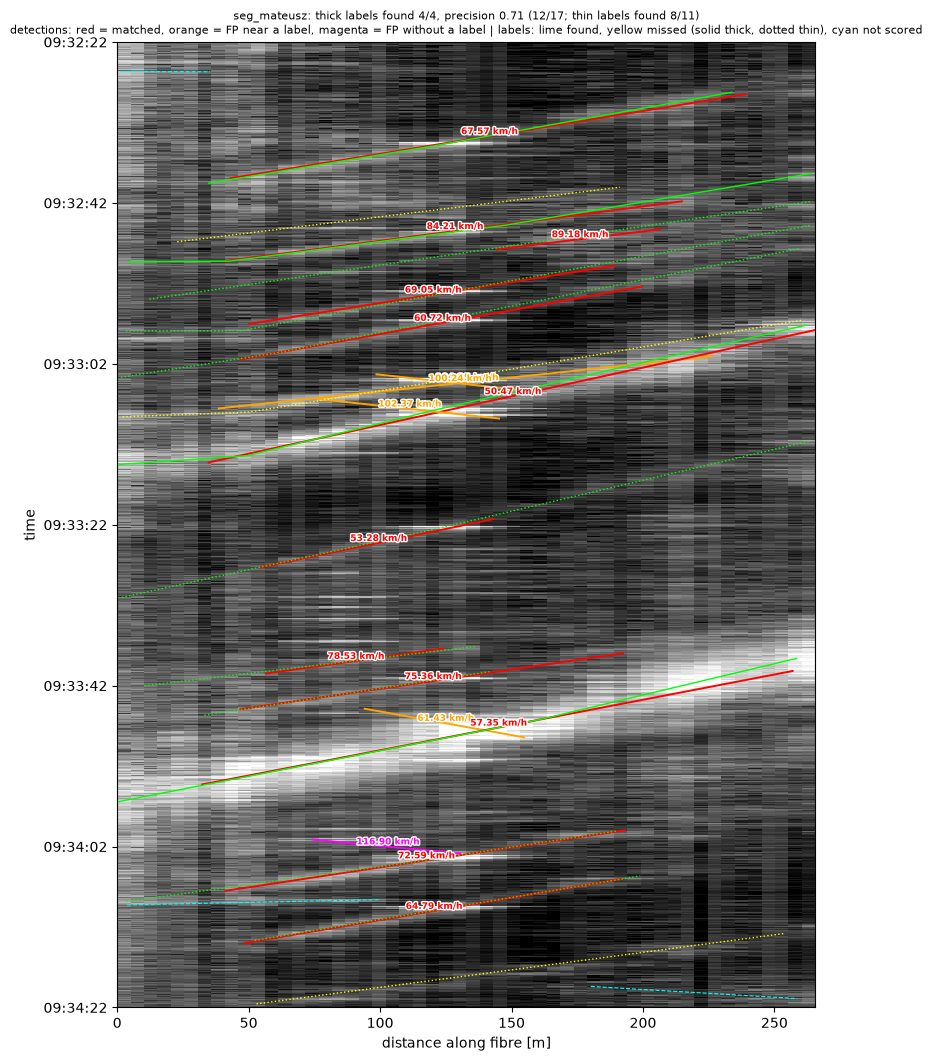

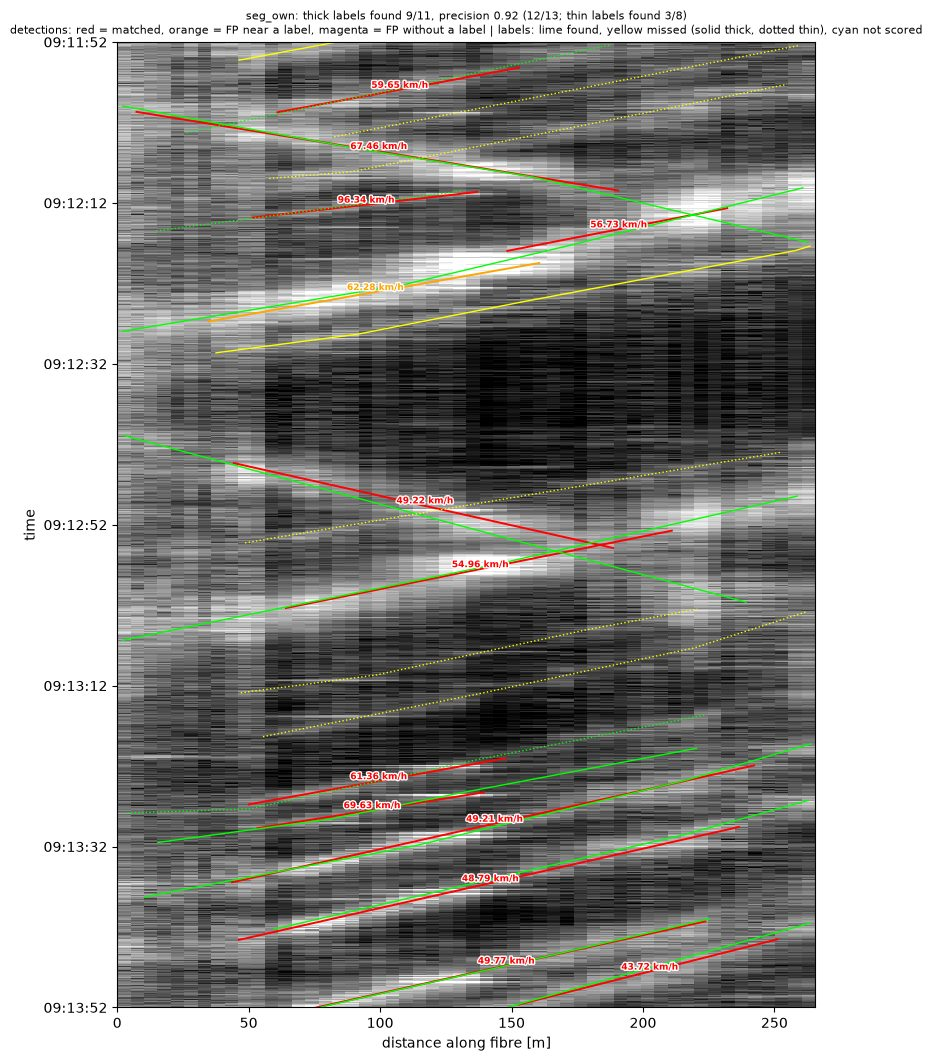

In [28]:
for s in ("seg_kuba", "seg_mateusz", "seg_own"):
    fig(f"eval_real_{s}", width=600)

In [29]:
ra = REAL["ALL"]
fp = int(ra["n_det"]) - int(ra["tp"])
display(Markdown(f"""
**Real result.**
- **{ra['tp_thick']} of {ra['n_ref_thick']}** thick lines were found (recall {f(ra['recall_thick'])}).
  All thick lines of seg_kuba and seg_mateusz were found; the misses are in seg_own, where lines
  of both directions cross.
- Precision {f(ra['precision'])}: {ra['tp']} of {ra['n_det']} detections match a labelled vehicle
  ({ra['tp_thin']} of them are loud cars with a thin label).
- Of the {fp} false positives, {ra['fp_near_label']} lie on a labelled line (fragments in the halo
  of a tram or pieces cut off at a crossing); {ra['fp_no_label']} have no label nearby.
- The velocity differs from the slope of the hand-drawn label by {f(ra['vel_mae_thick'], 1)} km/h
  on average for the thick lines, close to the accuracy of a hand-drawn slope.
"""))


**Real result.**
- **21 of 23** thick lines were found (recall 0.913).
  All thick lines of seg_kuba and seg_mateusz were found; the misses are in seg_own, where lines
  of both directions cross.
- Precision 0.791: 34 of 43 detections match a labelled vehicle
  (13 of them are loud cars with a thin label).
- Of the 9 false positives, 7 lie on a labelled line (fragments in the halo
  of a tram or pieces cut off at a crossing); 2 have no label nearby.
- The velocity differs from the slope of the hand-drawn label by 3.2 km/h
  on average for the thick lines, close to the accuracy of a hand-drawn slope.


### 10.2 Validation on the synthetic data (true ground truth)

| sample | detections | thick GT | thick found | thick recall | precision | F1 | thick \|v\| MAE [km/h] | thick MAPE [%] |
|---|---|---|---|---|---|---|---|---|
| 40 | 9 | 7 | 7 | 1.000 | 1.000 | 1.000 | 2.712 | 3.302 |
| 41 | 12 | 6 | 5 | 0.833 | 0.833 | 0.833 | 1.917 | 3.398 |
| 42 | 8 | 8 | 8 | 1.000 | 1.000 | 1.000 | 2.390 | 2.949 |
| 43 | 11 | 8 | 8 | 1.000 | 0.909 | 0.952 | 1.436 | 1.545 |
| 44 | 18 | 12 | 12 | 1.000 | 0.889 | 0.941 | 4.852 | 6.684 |
| 45 | 9 | 8 | 8 | 1.000 | 1.000 | 1.000 | 2.929 | 3.394 |
| ALL | 67 | 49 | 48 | 0.980 | 0.925 | 0.952 | 2.934 | 3.821 |

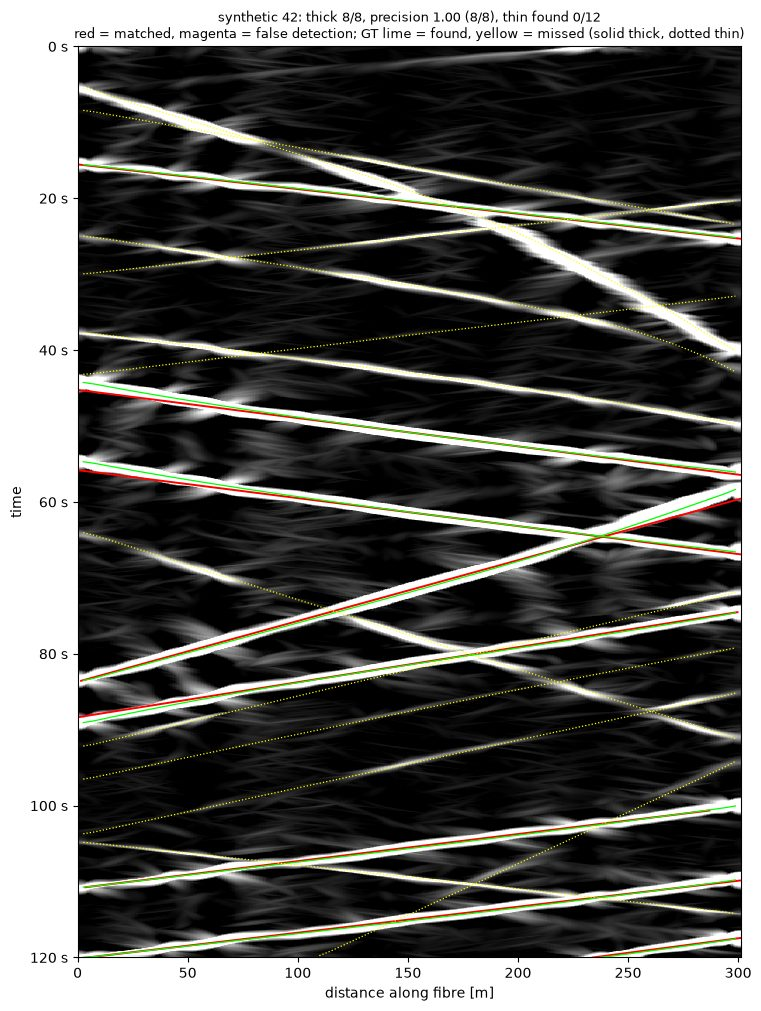


**Synthetic result.** **48 of 49** trams / trucks were found
(recall 0.980), precision 0.925. The velocity error of the thick
vehicles is **2.93 km/h** (MAPE 3.8 %). The
largest errors come from vehicles with a varying speed: one straight line is fitted to a slightly
curved trajectory.


In [30]:
table(read_csv("eval_synthetic.csv"),
      ["sample", "n_det", "n_ref_thick", "tp_thick", "recall_thick", "precision", "f1",
       "vel_mae_thick", "vel_mape_thick"],
      ["sample", "detections", "thick GT", "thick found", "thick recall", "precision", "F1",
       "thick |v| MAE [km/h]", "thick MAPE [%]"])
fig("eval_synthetic_42", width=560)
sa = SYN["ALL"]
display(Markdown(f"""
**Synthetic result.** **{sa['tp_thick']} of {sa['n_ref_thick']}** trams / trucks were found
(recall {f(sa['recall_thick'])}), precision {f(sa['precision'])}. The velocity error of the thick
vehicles is **{f(sa['vel_mae_thick'], 2)} km/h** (MAPE {f(sa['vel_mape_thick'], 1)} %). The
largest errors come from vehicles with a varying speed: one straight line is fitted to a slightly
curved trajectory.
"""))

## 11. Experiments

Every variant changes the final method in one place; the whole pipeline is then run on the 3
labelled real segments and the 6 synthetic samples and scored as in section 10.

**Selection rule.** The synthetic F1 (true ground truth) decides; a gain must exceed 0.01 (one
object ≈ 0.007). A gain is **vetoed** if the real F1 drops by more than 0.01 (it helps only the
simulator). The real labels never tune the method on their own - that would fit the method to
its own test reference.

In [31]:
exp = {r["variant"]: r for r in read_csv("experiments.csv")}
COLS = ["variant", "syn_recall_thick", "syn_precision", "syn_f1", "real_recall_thick",
        "real_precision", "real_f1", "decision"]
HEAD = ["variant", "syn thick R", "syn P", "syn F1", "real thick R", "real P", "real F1",
        "decision"]
display(Markdown("**Final method**"))
table([r for r in exp.values() if r["group"] == "final"], COLS, HEAD)
display(Markdown("**Ablation (one step switched off)**"))
table([r for r in exp.values() if r["group"] == "ablation"], COLS, HEAD)
# parameter values: one changed value per row, the final value in brackets
PARAMS = {
    "threshold floor 3 sigma": "threshold floor 3σ (final 4σ)",
    "threshold floor 6 sigma": "threshold floor 6σ (final 4σ)",
    "kernel length 41 px": "kernel length 41 px (final 81 px)",
    "upsampling x4": "upsampling along the cable ×4 (final ×8)",
    "min. component area 800 px": "min. component area 800 px (final 1500 px)",
    "grouping time tolerance 1 s": "grouping time tolerance 1 s (final 1.5 s)",
}
display(Markdown("**Parameter values (one value changed)**"))
table([{**exp[v], "variant": label} for v, label in PARAMS.items()], COLS, HEAD)

**Final method**

| variant | syn thick R | syn P | syn F1 | real thick R | real P | real F1 | decision |
|---|---|---|---|---|---|---|---|
| final method | 0.980 | 0.925 | 0.952 | 0.913 | 0.791 | 0.848 | final |

**Ablation (one step switched off)**

| variant | syn thick R | syn P | syn F1 | real thick R | real P | real F1 | decision |
|---|---|---|---|---|---|---|---|
| no common-mode removal | 0.980 | 0.884 | 0.929 | 0.870 | 0.762 | 0.812 | worse |
| no RMS envelope (plain decimation) | 0.980 | 0.909 | 0.943 | 0.870 | 0.725 | 0.791 | worse |
| no log compression (env / median) | 0.939 | 0.909 | 0.924 | 0.478 | 0.302 | 0.370 | worse |
| no f-k fan filter | 0.980 | 0.877 | 0.925 | 0.870 | 0.605 | 0.713 | worse |
| no directional filter bank | 0.959 | 0.877 | 0.916 | 0.652 | 0.750 | 0.698 | worse |
| no 4-sigma floor (Otsu only) | 0.980 | 0.925 | 0.952 | 1.000 | 0.381 | 0.552 | worse |
| one RANSAC line per component | 0.980 | 0.899 | 0.937 | 0.913 | 0.795 | 0.850 | worse |
| no linking of candidates (duplicate removal only) | 0.980 | 0.838 | 0.903 | 0.870 | 0.641 | 0.738 | worse |

**Parameter values (one value changed)**

| variant | syn thick R | syn P | syn F1 | real thick R | real P | real F1 | decision |
|---|---|---|---|---|---|---|---|
| threshold floor 3σ (final 4σ) | 0.980 | 0.925 | 0.952 | 1.000 | 0.528 | 0.691 | worse |
| threshold floor 6σ (final 4σ) | 0.980 | 0.925 | 0.952 | 0.609 | 0.815 | 0.697 | worse |
| kernel length 41 px (final 81 px) | 0.980 | 0.927 | 0.953 | 0.739 | 0.875 | 0.801 | worse |
| upsampling along the cable ×4 (final ×8) | 0.918 | 0.982 | 0.949 | 0.783 | 0.818 | 0.800 | worse |
| min. component area 800 px (final 1500 px) | 1.000 | 0.920 | 0.958 | 0.913 | 0.739 | 0.817 | worse |
| grouping time tolerance 1 s (final 1.5 s) | 0.980 | 0.925 | 0.952 | 0.913 | 0.660 | 0.766 | worse |

In [32]:
e = lambda v, c="real_f1": f(EXP[v][c])  # noqa: E731
display(Markdown(f"""
**What each step is responsible for** (F1 synthetic / real; final {e('final method', 'syn_f1')} /
{e('final method')}):
- **log compression** is the most important step: without it the real F1 drops to
  {e('no log compression (env / median)')}. The linear image is dominated by a few very strong cells.
- **f-k fan filter**: without it the real F1 is {e('no f-k fan filter')} (precision
  {e('no f-k fan filter', 'real_precision')}) - hotspot dashes and channel stripes become detections.
- **filter bank**: without it the real F1 is {e('no directional filter bank')} - diffuse tram lines
  do not reach the threshold as one piece.
- **4σ floor of the threshold**: without it the real precision is
  {e('no 4-sigma floor (Otsu only)', 'real_precision')}; a floor of 6σ loses real thick lines
  (recall {e('threshold floor 6 sigma', 'real_recall_thick')}).
- **common mode**, **RMS envelope**, **several RANSAC lines** and **linking of the candidates**
  each add a few F1 points, mostly in precision (fewer fragments).
- **Parameter values**: shorter kernels, a coarser upsampling, a smaller minimal component area or
  a shorter grouping tolerance each lower the real F1 (to {e('kernel length 41 px')},
  {e('upsampling x4')}, {e('min. component area 800 px')} and {e('grouping time tolerance 1 s')}).
"""))


**What each step is responsible for** (F1 synthetic / real; final 0.952 /
0.848):
- **log compression** is the most important step: without it the real F1 drops to
  0.370. The linear image is dominated by a few very strong cells.
- **f-k fan filter**: without it the real F1 is 0.713 (precision
  0.605) - hotspot dashes and channel stripes become detections.
- **filter bank**: without it the real F1 is 0.698 - diffuse tram lines
  do not reach the threshold as one piece.
- **4σ floor of the threshold**: without it the real precision is
  0.381; a floor of 6σ loses real thick lines
  (recall 0.609).
- **common mode**, **RMS envelope**, **several RANSAC lines** and **linking of the candidates**
  each add a few F1 points, mostly in precision (fewer fragments).
- **Parameter values**: shorter kernels, a coarser upsampling, a smaller minimal component area or
  a shorter grouping tolerance each lower the real F1 (to 0.801,
  0.800, 0.817 and 0.766).


## 12. Conclusions and limitations

**Conclusions.**
- The thick lines of trams and heavy trucks are found with a high recall on real and synthetic
  data, and their velocities are accurate to ≈ 3 km/h (synthetic ground truth).
- Every step and the key parameter values are justified by an experiment (section 11).
- The method is general: all thresholds are relative to the noise of each image and nothing
  refers to a specific line or segment. The same code runs on any 2-minute window and on the
  59-channel synthetic data. It is fast and fully vectorised.


**Limitations.**
- **No ground truth for real data.** The labels are rough clicks made by one annotator who also
  developed the method, and "thick" vs "thin" is subjective, so the real scores are indicative.
- **Synthetic ≠ real.** The simulator lacks the hotspot, tram halos and real noise, so synthetic
  scores are optimistic.
- **Loud cars pass the thick-line threshold.** The detector finds strong lines; it does not
  classify trams vs cars.
- **Crossings and tram halos** cause the missed thick lines and most false positives.
- **One straight line per vehicle**: the velocity is an average; a braking vehicle is described
  by its mean slope. A vehicle slower than 5 km/h (e.g. stopped at a tram stop) disappears.
- **Unknown cable geometry**: distances and velocities are along the fibre, not along the street.

## 13. References and sources

**Libraries** (allowed by the brief)
- **NumPy**: FFT (per-channel FFT, band-pass, Welch PSD, STFT, f-k), robust statistics, line fits.
- **OpenCV**: 2-D filtering (line-filter bank), resizing, grey-level dilation (ridge).
- **scikit-image**: Otsu threshold, connected components, RANSAC.
- **Matplotlib**: all figures and the labelling tool. Pillow was allowed but not needed.
- Tooling only: uv, pytest, Jupyter / nbconvert.

**Literature**
- M. A. Fischler, R. C. Bolles, *Random sample consensus*, Comm. ACM 24(6), 1981 - RANSAC.
- N. Otsu, *A threshold selection method from gray-level histograms*, IEEE Trans. SMC 9(1), 1979.
- S. Chaudhuri et al., *Detection of blood vessels in retinal images using two-dimensional matched
  filters*, IEEE Trans. Medical Imaging 8(3), 1989 - bank of rotated line kernels.
- Ö. Yilmaz, *Seismic Data Analysis*, SEG, 2001 - f-k (velocity) filtering.
- P. D. Welch, IEEE Trans. Audio and Electroacoustics 15(2), 1967 - Welch PSD.
- B. P. Welford, Technometrics 4(3), 1962; Chan, Golub, LeVeque, 1979 - running statistics.
- A. H. Hartog, *An Introduction to Distributed Optical Fibre Sensors*, CRC Press, 2017;
  N. J. Lindsey et al., Geophysical Research Letters 47(16), 2020 - DAS background, vehicles as
  slanted lines.